# Transplanting base-model plan states into Qwen3-8B: demo notebook

**Research question.** Qwen3-8B, the instruct model run with thinking off, writes the same algorithm for almost every coding task. Examples: a full sort for "k-th smallest", union-find for connected components, Dijkstra for weighted shortest paths. Its base model, Qwen3-8B-Base, is more varied on the *identical* prompt token ids. Is the lost variety still recoverable at the instruct model's internal **plan site**?

**Intervention: a cross-model state transplant.** This is cross-model activation patching. During the instruct model's prompt prefill, the hidden states of the task-specification tokens at decoder blocks 12-23 are **set** to

$$h[l,p] \leftarrow h_{instr}[l,p] + \lambda\,\big(h_{base}[l,p]-h_{instr}[l,p]\big),\qquad \lambda\in\{0.25,\,0.5,\,1\}$$

At λ = 1, the hooked blocks carry the base model's state exactly.

**Claim B** (pre-registered, causal): the transplant T(λ) reopens the base model's repertoire. To pass on a task, T(λ) must beat three controls on the *same* common-random-number (CRN) slots:
- **MR**: a norm-matched random direction;
- **XT**: another task's base-minus-instruct direction;
- **MRP**: a pass-matched random push.

It must also land on the base model's own runner-up algorithm r_t.

**What runs here.** The original `method.py` is a stage CLI. It drives about 1.7 GPU-hours of 8B-model sampling (vLLM and HF, bf16, RTX 4090), plus a label worker and LLM judges, which a Colab CPU cannot run. This notebook therefore:
1. runs the original **hook math** (`src/hooks5.py`) and its **CPU unit tests** (`tests/test_cpu.py`), after checking that both frozen modules are byte-identical to their COMMIT #0 hashes;
2. runs the original **engine hooks** (`src/engine5.py`: `block_hooks`, `prefill`) on a *tiny randomly initialised Qwen3 twin*, to show the transplant mechanics inside a transformer (engine unit tests U2/U3);
3. **replays** the real Stage-4 confirmation rows of tasks T14 and T03. That is 100 CRN slots of `method_out.json`, with the program Qwen3-8B wrote under each intervention. On these rows it re-runs the **frozen statistics and decision rule** (`src/analysis_b.py`, `src/analysis_final.py`): McNemar tests, Holm correction, the Claim-B rule, and the arm-shuffle placebo of `audit/rederive.py`;
4. redraws the composition, forest and plan-site activation-geometry figures (`src/figures5.py`).

**Full-run verdict: Claim B DISCONFIRMED** (PASS on 1 of 5 base-diverse tasks).
- **T14 (top-k frequent) passes.** Under T(1), the instruct model writes the base runner-up `heap` in 21 of 49 correct programs. The twin writes 0 of 39. All 21 are `Counter.most_common(k)`, which runs on `heapq`; that is also the base model's own main heap idiom (see §7).
- **T03 (k-th smallest) fails.** Matched-norm random noise moves the algorithm *more* than the base state does: 21 off-default programs out of 50, against 3 out of 50.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# Every package this notebook imports is pre-installed on Colab (numpy, scipy, matplotlib, torch, transformers),
# so nothing is installed there. Locally, install Colab's exact versions so the environment matches Colab.
if 'google.colab' not in sys.modules:
    _pip('torch==2.9.0+cpu', '--index-url', 'https://download.pytorch.org/whl/cpu',
         '--extra-index-url', 'https://pypi.org/simple')
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0',
         'transformers==5.0.0', 'tokenizers==0.22.2', 'huggingface_hub==1.4.0')

In [2]:
from __future__ import annotations

# method.py
import argparse
import subprocess
import sys
import time
from pathlib import Path

# src/analysis_final.py, src/engine5.py, src/gpu5.py, src/outputs5.py, src/cfg.py, audit/rederive.py, tests/test_cpu.py
import contextlib
import gc
import hashlib
import json
import math
import re
from collections import Counter, defaultdict
from typing import Any, Callable, Iterable, Iterator

import numpy as np
import torch
from scipy import stats
from scipy import stats as sps

# notebook additions: inline figures and program display
import matplotlib.pyplot as plt
import textwrap

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-5/experiment-24/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
EXAMPLES = data["datasets"][0]["examples"]   # one example per CRN slot (task, template W, slot j)
META = data["metadata"]                      # frozen commits, catalogues, geometry, full-run reference numbers
print(f'{data["datasets"][0]["dataset"]}: {len(EXAMPLES)} CRN slots', dict(Counter(e["metadata_task"] for e in EXAMPLES)))
print("example fields:", [k for k in EXAMPLES[0] if k != "metadata_programs"], "+ metadata_programs")
print("metadata blocks:", list(META))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
transplant_confirmation: 100 CRN slots {'T03': 50, 'T14': 50}
example fields: ['input', 'output', 'metadata_task', 'metadata_template', 'metadata_slot', 'metadata_crn_key', 'metadata_model', 'predict_MR1_0', 'predict_T1_0', 'predict_XT1_0'] + metadata_programs
metadata blocks: ['description', 'demo_tasks', 'models', 'commit0', 'commit1', 'commit2', 'catalogues', 'specificity', 'exp22_escape', 'geometry', 'reference_full_run']


## 0. Configuration

There are two blocks:
- **Design constants** of the experiment, copied verbatim from `src/cfg.py`. They define the experiment; do not change them.
- **Demo-scale knobs.** The full run's value of each knob is in its comment.

The paths mirror `method.py` (`ROOT`, `SRC`). The two frozen modules are written to `src/` by the cells below, and imported from there exactly as the original scripts import them.

In [5]:
# ---- design constants of the experiment (src/cfg.py, verbatim) ----
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
BASE_ID = "Qwen/Qwen3-8B-Base"
BASE_REVISION = "49e3418fbbbca6ecbdf9608b4d22e5a407081db4"   # ITER1 exp5 reproducibility.md (pinned for comparability)
N_LAYERS = 36
D_MODEL = 4096
IM_END = 151645
ENDOFTEXT = 151643
PATH_TASKS = ("T1", "T2")
TEMPLATE_IDS = ["W1", "W2", "W3", "W4", "W5"]
V_BLOCKS = list(range(12, 24))          # transplant / push band (task-spec positions, prefill only)
EARLY_BLOCKS = list(range(0, 12))
LATE_BLOCKS = list(range(24, 36))
S1_SLOTS = list(range(10))              # selection slots j = 0..9 (N = 50 per task)
S2_SLOTS_100 = list(range(10, 30))      # confirmation slots (N = 100)
S2_SLOTS_50 = list(range(10, 20))       # confirmation slots (N = 50)
LAMBDAS = (0.25, 0.5, 1.0)
BETA_DIVERSE = 0.20
BETA_COLLAPSED = 0.05
PASS_FRAC = 0.8
DEPTH = 25

# ---- demo scale (full-run value in the comment) ----
DEMO_TASKS = META["demo_tasks"]   # T03, T14 (full run: the 5 decisive + 7 descriptive Stage-4 tasks)
N_RAREFY = 1000                   # rarefied Hill-1 subsamples per arm cell (full run: 1000)
N_MCNEMAR_SIMS = 200              # test_cpu: arm-shuffled McNemar simulations (full run: 200)
N_BETA_SIMS = 100                 # test_cpu: bootstrap-coverage simulations (full run: 100)
BETA_BOOT_B = 300                 # test_cpu: bootstrap resamples per simulation (full run: 300)
N_PLACEBO_SHUFFLES = 200          # rederive: arm shuffles per decisive task (full run: 200)
# toy Qwen3 twin for the hooked-prefill demo; the full run uses Qwen3-8B / -Base on a GPU:
# 36 blocks, d_model 4096, 32 heads (8 KV heads), vocabulary 151,936, ~100-150-token twin prompts, band 12-23
TOY_LAYERS = 9
TOY_D = 64
TOY_HEADS = 4
TOY_KV_HEADS = 2
TOY_VOCAB = 512
TOY_PROMPT_LEN = 32
TOY_BLOCKS = [3, 4, 5]               # hooked band (the middle third, like blocks 12-23 of 36)
TOY_SPEC = (6, 26)                # task-spec positions S = [p1, spec_end); R = P - 1
TOY_SEED = 0

# method.py paths (ROOT = this notebook's folder instead of Path(__file__))
ROOT = Path.cwd()
SRC = ROOT / "src"
SRC.mkdir(exist_ok=True)
sys.path.insert(0, str(SRC))

## The original entry point: `method.py`

The artifact is driven by a resumable stage CLI. Each stage shells out to a script in `src/`. The GPU stages hold one 8B model at a time. Here is `method.py`, verbatim:

```python
#!/usr/bin/env python3
"""Stage CLI of the iteration-5 'transplanting the base model's plan' artifact (resumable: every stage skips the
rows / files it has already written; GPU stages hold one 8B model at a time).

  .venv/bin/python method.py --stage 0   prompts (src/prompts5.py), Stage-0 checks (src/s0.py), CPU unit tests
  .venv/bin/python method.py --stage 1   base repertoire with vLLM (src/base_vllm.py, .venv_vllm) + label worker
  .venv/bin/python method.py --stage 2   instruct engine check / twin / states (src/gpu5.py instr1), COMMIT #0
  .venv/bin/python method.py --stage 3   base audit (src/audit5.py base), COMMIT #1 (src/commits5.py 1)
  .venv/bin/python method.py --stage 4   base states + Stage 6 reverse interchange (src/gpu5.py base1)
  .venv/bin/python method.py --stage 5   Stage 3 selection, Stage 5 push, COMMIT #2, Stage 4 confirmation
                                         (src/gpu5.py instr2)
  .venv/bin/python method.py --stage 8   analyses, geometry, novelty audit, figures, outputs, re-derivation
The label worker (src/labels5.py --follow) must run beside stages 1-5; `--stage all` runs everything in order.
"""

from __future__ import annotations

import argparse
import subprocess
import sys
import time
from pathlib import Path

ROOT = Path(__file__).resolve().parent
PY = str(ROOT / ".venv" / "bin" / "python")
PYV = str(ROOT / ".venv_vllm" / "bin" / "python")
SRC = ROOT / "src"


def run(cmd: list[str]) -> None:
    print(f"$ {' '.join(cmd)}", flush=True)
    t0 = time.time()
    subprocess.run(cmd, cwd=SRC, check=True)
    print(f"  done in {time.time() - t0:.0f}s", flush=True)


def start_labeller() -> subprocess.Popen:
    return subprocess.Popen([PY, "labels5.py", "--follow"], cwd=SRC,
                            stdout=open(ROOT / "logs" / "labels5.out", "a"), stderr=subprocess.STDOUT)


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--stage", default="all", choices=["0", "1", "2", "3", "4", "5", "8", "all"])
    a = ap.parse_args()
    st = a.stage
    lab = None
    if st in ("1", "2", "3", "4", "5", "all"):
        lab = start_labeller()
    try:
        if st in ("0", "all"):
            run([PY, "prompts5.py"])
            run([PY, "s0.py"])
            run([PY, str(ROOT / "tests" / "test_cpu.py")])
        if st in ("1", "all"):
            run([PYV, "base_vllm.py", "--stage", "all"])
        if st in ("2", "all"):
            run([PY, "gpu5.py", "instr1"])
            run([PY, "commits5.py", "0"])
        if st in ("3", "all"):
            run([PY, "audit5.py", "base"])
            run([PY, "commits5.py", "1"])
        if st in ("4", "all"):
            run([PY, "gpu5.py", "base1", "--wait-min", "5"])
        if st in ("5", "all"):
            run([PY, "gpu5.py", "instr2", "--wait-min", "40"])
        if st in ("8", "all"):
            (ROOT / "data" / "labels_stop.flag").write_text("stop")
            run([PY, "analysis_final.py"])
            run([PY, "geometry5.py", "all"])
            run([PY, "audit5.py", "novelty"])
            run([PY, "analysis_final.py"])
            run([PY, "figures5.py"])
            run([PY, "outputs5.py"])
            run([PY, str(ROOT / "audit" / "rederive.py")])
    finally:
        if lab is not None and st != "all":
            lab.terminate()


if __name__ == "__main__":
    sys.exit(main())
```

How each stage appears in this notebook:

| `--stage` | original command(s) | needs | in this notebook |
|---|---|---|---|
| 0 | `prompts5.py`, `s0.py`, `tests/test_cpu.py` | CPU | **§1**: frozen hook math and statistics, then `test_cpu.py`, run as-is |
| 1 | `base_vllm.py` (Qwen3-8B-Base chat and plain sampling) + label worker | GPU | replayed: the base composition counts frozen in COMMIT #1 (§3) |
| 2 | `gpu5.py instr1` (engine check, twin, prefill states), COMMIT #0 | GPU | **§2**: original engine hooks on a toy Qwen3 twin (tests U2/U3) |
| 3 | `audit5.py base` (judge audit), `commits5.py 1` (COMMIT #1) | CPU + API | **§3**: default_t, β_t, r_t and strata re-derived |
| 4 | `gpu5.py base1` (base states, reverse interchange) | GPU | not shown (README of the artifact) |
| 5 | `gpu5.py instr2` (selection, COMMIT #2, **Stage-4 confirmation**, Claim D) | GPU | **§4**: real Stage-4 labels replayed; confirmation statistics re-run |
| 8 | `analysis_final.py`, `geometry5.py`, `audit5.py novelty`, `figures5.py`, `outputs5.py`, `audit/rederive.py` | CPU + API | **§4-§7**: confirmation, re-derivation and placebo, figures, summary |

## 1. Stage 0: the hook math (`src/hooks5.py`)

Every intervention is a **block-output edit**. It is applied during the prompt prefill only, at the hooked blocks' outputs, with fp32 math cast back to bf16. Notation:
- `h_ref` is the recipient model's cached clean state for the same prompt;
- `D[l,p] = h_donor[l,p] - h_recipient[l,p]`, which is base minus instruct for the forward transplant.

| kind | edit at each hooked (block l, position p) | role |
|---|---|---|
| **SET(λ)** = T(λ) | `h ← h_ref + λ·D` | the transplant; λ = 1 gives the donor's state |
| **MR(λ)** | `h ← h_ref + λ·‖D‖·u_s` | norm-matched random; one isotropic unit u_s per sample |
| **XT(λ)** | `h ← h_ref + λ·‖D_t‖·unit(D̄_partner)` | cross-task content control |
| **DS(α) / ISO(α)** | set the component along unit(D) or u_s to α·n (n = one ban-free unit) | Claim D, the de-sharpening push |

SET-TO edits **replace** the hooked state rather than add to it, so nothing compounds across the hooked blocks. The cell below writes the module **byte-for-byte** to `src/hooks5.py`.

In [6]:
%%writefile src/hooks5.py
#!/usr/bin/env python3
"""Block-output edits of this artifact (all applied in the PROMPT PREFILL only, at the hooked blocks' outputs;
fp32 math, cast back to the model dtype). h_ref = the cached clean state of the RECIPIENT model for the same prompt;
D[l,p] = h_donor[l,p] - h_recipient[l,p] (base minus instruct for the forward transplant).

SETTO kinds (the hooked state is SET, so it is independent of the upstream state: nothing compounds):
  SET(lam):  h[l,p] <- h_ref[l,p] + lam * D[l,p]                               (transplant; lam = 1 -> donor state)
  MR(lam):   h[l,p] <- h_ref[l,p] + lam * ||D[l,p]|| * u_s                      (norm-matched random; one isotropic unit
                                                                                 u_s per sample, shared by all blocks
                                                                                 and positions)
  XT(lam):   h[l,p] <- h_ref[l,p] + lam * ||D_t[l,p]|| * unit(Dbar_partner[l])  (cross-task content control)
ALONG kinds (exp19 ADD/PN: displacement-targeted along a unit direction; orthogonal components left free):
  DS(alpha): h <- h + (alpha * n[l,p] - (h - h_ref) . d[l,p]) d[l,p],  d = D / ||D|| per (l,p)
  ISO(alpha): the same with one isotropic unit u_s per sample;  n[l,p] = ||h_instr[l,p]|| * r_Q(l) (ban-free unit)
  EC_RAND:   exp17 engine-check push: one fixed direction, exp17 ban unit n[l,p]
"""

from __future__ import annotations

from typing import Callable

import torch


def edits_setto(blocks: list[int], idx: torch.Tensor, targets: dict[int, torch.Tensor]
                ) -> dict[int, Callable[[torch.Tensor], torch.Tensor]]:
    """targets: {l: fp32 [len(idx), D]} -> h[:, idx] = target (batch-1 prefill)."""
    edits = {}
    for l in blocks:
        def f(h: torch.Tensor, l: int = l) -> torch.Tensor:
            h = h.clone()
            h[:, idx] = targets[l].to(h.dtype)[None]
            return h
        edits[l] = f
    return edits


def edits_along(blocks: list[int], idx: torch.Tensor, dirs: dict[int, torch.Tensor], tgt: dict[int, torch.Tensor],
                h_ref: dict[int, torch.Tensor]) -> dict[int, Callable[[torch.Tensor], torch.Tensor]]:
    """dirs: {l: fp32 [len(idx), D] unit rows or [D]}; tgt: {l: fp32 [len(idx)]}; h_ref: {l: fp32 [len(idx), D]}."""
    edits = {}
    for l in blocks:
        def f(h: torch.Tensor, l: int = l) -> torch.Tensor:
            hs = h[:, idx].float()                                  # [1, n, D]
            d = dirs[l] if dirs[l].dim() == 2 else dirs[l][None].expand(hs.shape[1], -1)
            comp = ((hs - h_ref[l][None]) * d[None]).sum(-1)        # [1, n]
            coef = tgt[l][None] - comp
            new = hs + coef[..., None] * d[None]
            h = h.clone()
            h[:, idx] = new.to(h.dtype)
            return h
        edits[l] = f
    return edits


def unit_rows(x: torch.Tensor, eps: float = 1e-8) -> torch.Tensor:
    return x / x.norm(dim=-1, keepdim=True).clamp(min=eps)

Overwriting src/hooks5.py


### The frozen statistics and decision rules (`src/analysis_b.py`)

This file holds every statistic and pre-registered rule. Its sha256 was hash-committed in **COMMIT #0**, before any transplant, control or push sample was drawn. The core definitions:
- **correct(r)**: the program passed every hidden test and was extracted.
- **default_t**: the instruct twin's modal correct algorithm on the S1 slots, if its share is at least 0.6.
- **y(slot)** = 1[correct ∧ catalogue label ≠ default_t]. This is the per-slot outcome every McNemar test compares.
- **β_t**: the off-default share among the base model's correct chat programs.
- **Strata**: BASE-DIVERSE if β ≥ 0.20, BASE-COLLAPSED if β < 0.05, INTERMEDIATE otherwise.
- **r_t**: the base model's most frequent correct non-default algorithm, its *runner-up*.

The tests are the one-sided exact McNemar test on discordant pairs, Holm correction, Wilson and Newcombe intervals, and a template-cluster bootstrap for β.

In [7]:
%%writefile src/analysis_b.py
#!/usr/bin/env python3
"""Frozen analysis code (sha256 committed in COMMIT #0): statistics and the pre-registered decision rules for
Claim B (transplant reopens the base repertoire), Claim D (de-sharpening push) and the reverse interchange.

Definitions (also restated in predictions/commit0.json):
- correct(r)       := passed every hidden test AND a program was extracted (label != 'invalid').
- catalogue label  := a label in the task's catalogue; 'other' and 'invalid' are never catalogue labels.
- off-default share (among correct) := n(correct, catalogue label != default_t) / n(correct); 'other' stays in the
                      denominator only.
- y(slot)          := 1[correct AND catalogue label != default_t] (per CRN slot; the McNemar outcome).
- default_t        := modal correct label of the S1 twin if its share among correct >= 0.6, else None.
- beta_t           := off-default share of the BASE_CHAT programs w.r.t. default_t (fewer than 20 correct even after
                      the top-up -> the same share over parseable attempts, flagged ATTEMPT).
- r_t              := the most frequent correct non-default catalogue label of BASE_CHAT (ties: more attempts, then
                      alphabetical).
- strata           := BASE-DIVERSE beta >= 0.20; BASE-COLLAPSED beta < 0.05; INTERMEDIATE otherwise.
Tests: one-sided exact McNemar = binomial(b, b + c, 1/2) upper tail on the discordant pairs of y; Holm over the
decisive family; Wilson intervals for shares, Newcombe (hybrid score) intervals for differences.
"""

from __future__ import annotations

import math
from collections import Counter
from typing import Any, Iterable

import numpy as np
from scipy import stats as sps

NON_CATALOGUE = {"other", "invalid", None, "unknown", "unresolved", "no_code"}


# ------------------------------------------------------------------------------------------------ row helpers
def is_correct(r: dict[str, Any]) -> bool:
    return bool(r.get("passed")) and r.get("label") not in ("invalid", None)


def is_valid(r: dict[str, Any]) -> bool:
    return r.get("label") not in ("invalid", None)


def cat_label(r: dict[str, Any], cat: Iterable[str]) -> str | None:
    lab = r.get("label")
    return lab if lab in set(cat) else None


def y_off(r: dict[str, Any], default: str | None, cat: Iterable[str]) -> int:
    lab = cat_label(r, cat)
    return int(is_correct(r) and lab is not None and default is not None and lab != default)


def z_def(r: dict[str, Any], default: str | None) -> int:
    return int(is_correct(r) and default is not None and r.get("label") == default)


def composition(rows: list[dict[str, Any]], correct_only: bool = True) -> dict[str, int]:
    c = Counter(r.get("label") for r in rows if (is_correct(r) if correct_only else is_valid(r)))
    return dict(sorted(c.items(), key=lambda kv: (-kv[1], str(kv[0]))))


def off_share(rows: list[dict[str, Any]], default: str | None, cat: Iterable[str],
              attempts: bool = False) -> tuple[float | None, int, int]:
    """(share, k, n): among correct programs (attempts=True: among parseable attempts)."""
    pool = [r for r in rows if (is_valid(r) if attempts else is_correct(r))]
    cs = set(cat)
    k = sum(1 for r in pool if r.get("label") in cs and r.get("label") != default)
    return (k / len(pool) if pool else None), k, len(pool)


def default_share(rows: list[dict[str, Any]], default: str | None, attempts: bool = False
                  ) -> tuple[float | None, int, int]:
    pool = [r for r in rows if (is_valid(r) if attempts else is_correct(r))]
    k = sum(1 for r in pool if r.get("label") == default)
    return (k / len(pool) if pool else None), k, len(pool)


def pass_rate(rows: list[dict[str, Any]]) -> tuple[float | None, int, int]:
    n = len(rows)
    k = sum(is_correct(r) for r in rows)
    return (k / n if n else None), k, n


# ------------------------------------------------------------------------------------------------ diversity
def hill1(counts: dict[str, int] | Counter) -> float | None:
    v = np.array([c for c in counts.values() if c > 0], dtype=float)
    if v.sum() == 0:
        return None
    p = v / v.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def rarefied_hill1(labels: list[str], depth: int = 25, n_sub: int = 1000, seed: int = 20261021
                   ) -> dict[str, Any]:
    """Mean Hill-1 over n_sub subsamples of `depth` correct programs without replacement (fewer: all, flagged)."""
    n = len(labels)
    if n == 0:
        return {"hill1": None, "n": 0, "flag_below_depth": True}
    if n <= depth:
        return {"hill1": hill1(Counter(labels)), "n": n, "flag_below_depth": n < depth}
    rng = np.random.default_rng(seed)
    arr = np.array(labels, dtype=object)
    vals = []
    for _ in range(n_sub):
        sub = arr[rng.choice(n, size=depth, replace=False)]
        vals.append(hill1(Counter(sub.tolist())))
    return {"hill1": float(np.mean(vals)), "n": n, "flag_below_depth": False}


# ------------------------------------------------------------------------------------------------ intervals
def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float | None, float | None]:
    if n == 0:
        return None, None
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return max(0.0, c - h), min(1.0, c + h)


def newcombe(k1: int, n1: int, k2: int, n2: int) -> dict[str, float | None]:
    """Newcombe (1998) method 10 hybrid score interval for p1 - p2 (independent proportions)."""
    if n1 == 0 or n2 == 0:
        return {"diff": None, "lo": None, "hi": None}
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson(k1, n1)
    l2, u2 = wilson(k2, n2)
    d = p1 - p2
    lo = d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2)
    hi = d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)
    return {"diff": d, "lo": lo, "hi": hi}


# ------------------------------------------------------------------------------------------------ tests
def mcnemar_exact(a: list[int], b: list[int]) -> dict[str, Any]:
    """Paired binary outcomes (same CRN slots): H1 one-sided a > b. b_ = #(a=1, b=0), c_ = #(a=0, b=1)."""
    assert len(a) == len(b)
    b_ = sum(1 for x, y in zip(a, b) if x == 1 and y == 0)
    c_ = sum(1 for x, y in zip(a, b) if x == 0 and y == 1)
    n = b_ + c_
    if n == 0:
        return {"b": 0, "c": 0, "n_pairs": len(a), "p_one": 1.0, "p_two": 1.0}
    p_one = float(sps.binom.sf(b_ - 1, n, 0.5))
    p_two = float(min(1.0, 2 * min(sps.binom.cdf(b_, n, 0.5), sps.binom.sf(b_ - 1, n, 0.5))))
    return {"b": b_, "c": c_, "n_pairs": len(a), "p_one": p_one, "p_two": p_two}


def binom_upper(k: int, n: int, p0: float) -> float:
    if n == 0:
        return 1.0
    return float(sps.binom.sf(k - 1, n, min(max(p0, 1e-12), 1 - 1e-12)))


def holm(pvals: dict[str, float]) -> dict[str, float]:
    keys = sorted(pvals, key=lambda k: pvals[k])
    m = len(keys)
    out: dict[str, float] = {}
    run = 0.0
    for i, k in enumerate(keys):
        adj = min(1.0, (m - i) * pvals[k])
        run = max(run, adj)
        out[k] = run
    return out


def pair_rows(a_rows: list[dict[str, Any]], b_rows: list[dict[str, Any]]) -> list[tuple[dict, dict]]:
    """Pair rows of two arms on the same (template, slot)."""
    bm = {(r["template"], int(r["slot"])): r for r in b_rows}
    out = []
    for r in a_rows:
        k = (r["template"], int(r["slot"]))
        if k in bm:
            out.append((r, bm[k]))
    return sorted(out, key=lambda p: (p[0]["template"], int(p[0]["slot"])))


def template_robustness(a_rows: list[dict[str, Any]], b_rows: list[dict[str, Any]], default: str | None,
                        cat: Iterable[str]) -> dict[str, Any]:
    cat = list(cat)
    out = {}
    n_gt = 0
    for w in sorted({r["template"] for r in a_rows}):
        ya = [y_off(r, default, cat) for r in a_rows if r["template"] == w]
        yb = [y_off(r, default, cat) for r in b_rows if r["template"] == w]
        ra = float(np.mean(ya)) if ya else None
        rb = float(np.mean(yb)) if yb else None
        out[w] = {"y_rate_arm": ra, "y_rate_control": rb}
        n_gt += int(ra is not None and rb is not None and ra > rb)
    return {"by_template": out, "n_templates_arm_gt_control": n_gt, "n_templates": len(out)}


# ------------------------------------------------------------------------------------------------ base repertoire
def default_from_twin(rows: list[dict[str, Any]], min_share: float = 0.6) -> tuple[str | None, float | None]:
    comp = composition(rows)
    n = sum(comp.values())
    if n == 0:
        return None, None
    lab, k = max(comp.items(), key=lambda kv: (kv[1], str(kv[0]) == "other" and -1 or 0, str(kv[0])))
    share = k / n
    if lab in NON_CATALOGUE or share < min_share:
        return None, share
    return lab, share


def runner_up(rows: list[dict[str, Any]], default: str | None, cat: Iterable[str]) -> str | None:
    cs = set(cat)
    corr = Counter(r["label"] for r in rows if is_correct(r) and r.get("label") in cs and r["label"] != default)
    if not corr:
        return None
    att = Counter(r["label"] for r in rows if is_valid(r) and r.get("label") in cs)
    return sorted(corr, key=lambda m: (-corr[m], -att.get(m, 0), m))[0]


def stratum(beta: float | None, diverse: float = 0.20, collapsed: float = 0.05) -> str | None:
    if beta is None:
        return None
    if beta >= diverse:
        return "BASE-DIVERSE"
    if beta < collapsed:
        return "BASE-COLLAPSED"
    return "INTERMEDIATE"


def base_beta(rows: list[dict[str, Any]], default: str | None, cat: Iterable[str], min_correct: int = 20
              ) -> dict[str, Any]:
    s, k, n = off_share(rows, default, cat)
    flag = n < min_correct
    if flag:
        s2, k2, n2 = off_share(rows, default, cat, attempts=True)
        return {"beta": s2, "k": k2, "n": n2, "basis": "ATTEMPT", "n_correct": n, "beta_correct_only": s}
    return {"beta": s, "k": k, "n": n, "basis": "CORRECT", "n_correct": n}


def beta_bootstrap(rows: list[dict[str, Any]], default: str | None, cat: Iterable[str], B: int = 2000,
                   seed: int = 20261021, min_correct: int = 20) -> dict[str, Any]:
    """Template-cluster bootstrap: resample the 5 templates with replacement (all rows of a template together)."""
    by_w: dict[str, list[dict[str, Any]]] = {}
    for r in rows:
        by_w.setdefault(r["template"], []).append(r)
    ws = sorted(by_w)
    rng = np.random.default_rng(seed)
    point = base_beta(rows, default, cat, min_correct)
    st0 = stratum(point["beta"])
    vals, same = [], 0
    for _ in range(B):
        pick = rng.choice(len(ws), size=len(ws), replace=True)
        rr = [r for i in pick for r in by_w[ws[i]]]
        b = base_beta(rr, default, cat, min_correct)["beta"]
        if b is None:
            continue
        vals.append(b)
        same += int(stratum(b) == st0)
    if not vals:
        return {"ci": [None, None], "stability": None, "n_boot": 0}
    return {"ci": [float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))],
            "stability": same / len(vals), "n_boot": len(vals)}


def smoothed_landing(rows: list[dict[str, Any]], default: str | None, cat: Iterable[str]) -> dict[str, float]:
    modes = [m for m in cat if m != default]
    c = Counter(r["label"] for r in rows if is_correct(r) and r.get("label") in set(modes))
    tot = sum(c.values()) + 0.5 * len(modes)
    return {m: (c.get(m, 0) + 0.5) / tot for m in modes} if modes else {}


def derangement(tasks: list[str], seed: int) -> dict[str, str]:
    """Seeded random derangement (no fixed points) by rejection sampling of permutations."""
    rng = np.random.default_rng(seed)
    ts = sorted(tasks)
    if len(ts) < 2:
        return {}
    while True:
        perm = rng.permutation(len(ts))
        if all(perm[i] != i for i in range(len(ts))):
            return {ts[i]: ts[int(perm[i])] for i in range(len(ts))}


# ------------------------------------------------------------------------------------------------ rules
def select_lambda(cells: dict[float, dict[str, Any]], twin_pass: float, frac: float = 0.8) -> float | None:
    """cells[lam] = {'pass': p, 'off_share': s}; lam* = argmax off_share among lam with pass >= frac * twin_pass;
    ties -> the smaller lambda; none -> None (UNTESTED)."""
    ok = [(lam, c) for lam, c in cells.items() if c.get("pass") is not None and c["pass"] >= frac * twin_pass
          and c.get("off_share") is not None]
    if not ok:
        return None
    best = max(c["off_share"] for _, c in ok)
    return min(lam for lam, c in ok if c["off_share"] == best)


def broken(pass_arm: float | None, twin_pass: float, frac: float = 0.8) -> bool:
    return pass_arm is None or pass_arm < frac * twin_pass


def claim_b_task(*, beta: float, r_t: str | None, pass_T: float, pass_twin: float, offshare_T: float | None,
                 p_holm: dict[str, float], mr_broke: bool, modal_T: str | None) -> dict[str, Any]:
    c1 = pass_T >= 0.8 * pass_twin
    c2 = offshare_T is not None and offshare_T >= 0.5 * beta
    need = ["MR", "XT"] + (["MRp"] if mr_broke else [])
    c3 = all(p_holm.get(k, 1.0) < 0.05 for k in need)
    c3_mr = p_holm.get("MR", 1.0) < 0.05 and (not mr_broke or p_holm.get("MRp", 1.0) < 0.05)
    c3_xt = p_holm.get("XT", 1.0) < 0.05
    c4 = modal_T is not None and modal_T == r_t
    return {"i_pass": c1, "ii_share": c2, "iii_controls": c3, "iii_vs_MR": c3_mr, "iii_vs_XT": c3_xt,
            "iv_landing": c4, "PASS": bool(c1 and c2 and c3 and c4), "controls_required": need}


def claim_b_verdict(task_res: dict[str, dict[str, Any]], n_div: int, specificity: bool, valid: bool
                    ) -> dict[str, Any]:
    if not valid:
        return {"verdict": "UNTESTED", "reason": "validity gate failed"}
    if n_div < 3:
        return {"verdict": "DESCRIPTIVE", "reason": f"only {n_div} BASE-DIVERSE tasks with a default (< 3)"}
    dec = {t: r for t, r in task_res.items() if r.get("decisive")}
    n_pass = sum(1 for r in dec.values() if r["rule"]["PASS"])
    need = math.ceil(2 * n_div / 3)
    n_iii_fail = sum(1 for r in dec.values() if not r["rule"]["iii_controls"])
    pass_ok = all(r["rule"]["i_pass"] for r in dec.values())
    if n_pass >= need and specificity:
        v = "CONFIRMED"
    elif pass_ok and n_iii_fail > len(dec) / 3:
        v = "DISCONFIRMED"
    else:
        v = "PARTIAL"
    branches = []
    if v == "PARTIAL":
        if any(r["rule"]["iii_vs_MR"] and not r["rule"]["iii_vs_XT"] for r in dec.values()):
            branches.append("beats MR but not XT -> a generic base shift reopens")
        if not specificity:
            branches.append("specificity failed (READ moves or collapsed tasks move)")
        if any(r["rule"]["iii_controls"] and not r["rule"]["iv_landing"] for r in dec.values()):
            branches.append("lands off r_t -> reopens, but not the base runner-up")
    return {"verdict": v, "n_decisive": len(dec), "n_pass": n_pass, "needed": need, "n_iii_fail": n_iii_fail,
            "specificity": specificity, "branches": branches}


def escapes(*, k_off: int, n: int, off_share_arm: float | None, off_share_twin: float, pass_arm: float,
            pass_twin: float, twin_k: int, twin_n: int) -> dict[str, Any]:
    """Claim D cell rule: off-default share (among correct) >= twin + 0.20 AND pass >= 0.8 x twin AND one-sided exact
    binomial p < 0.05 of k_off (correct off-default slots out of n) against the twin's smoothed per-slot rate
    p0 = (twin_k + 0.5) / (twin_n + 1)."""
    p0 = (twin_k + 0.5) / (twin_n + 1)
    p = binom_upper(k_off, n, p0)
    ok = (off_share_arm is not None and off_share_arm >= off_share_twin + 0.20 and pass_arm >= 0.8 * pass_twin
          and p < 0.05)
    return {"escapes": bool(ok), "p_binom": p, "p0": p0}


def claim_d_task(a_ds: float | None, a_iso: float | None, ds_landing: str | None, r_t: str | None) -> dict[str, Any]:
    if a_ds is None:
        return {"PASS": False, "reason": "DS never escapes"}
    if a_iso is None:  # ISO censored above 2
        ok = a_ds <= 1.0
    else:
        ok = a_ds <= 0.5 * a_iso
    return {"PASS": bool(ok and ds_landing == r_t), "dose_ok": bool(ok), "landing_ok": ds_landing == r_t}


def claim_d_verdict(task_res: dict[str, dict[str, Any]]) -> dict[str, Any]:
    if not task_res:
        return {"verdict": "UNTESTED"}
    n = len(task_res)
    n_pass = sum(1 for r in task_res.values() if r["rule"]["PASS"])
    better = sum(1 for r in task_res.values()
                 if r["a_ds"] is not None and (r["a_iso"] is None or r["a_ds"] < r["a_iso"]))
    if n_pass >= math.ceil(2 * n / 3):
        v = "CONFIRMED"
    elif better == 0:
        v = "DISCONFIRMED"
    else:
        v = "PARTIAL"
    return {"verdict": v, "n_tasks": n, "n_pass": n_pass, "n_ds_earlier_than_iso": better}


def reverse_prediction(share_rt: float | None, share_btwin: float | None, share_instr_twin: float | None
                       ) -> dict[str, Any]:
    if None in (share_rt, share_btwin, share_instr_twin):
        return {"met": None}
    need = share_btwin + 0.5 * (share_instr_twin - share_btwin)
    return {"met": bool(share_rt >= need), "threshold": need, "rise": share_rt - share_btwin,
            "predicted_min_rise": 0.5 * (share_instr_twin - share_btwin)}


def jsd(p: dict[str, int], q: dict[str, int]) -> float:
    keys = sorted(set(p) | set(q), key=str)
    a = np.array([p.get(k, 0) for k in keys], float)
    b = np.array([q.get(k, 0) for k in keys], float)
    if a.sum() == 0 or b.sum() == 0:
        return float("nan")
    a, b = a / a.sum(), b / b.sum()
    m = (a + b) / 2

    def kl(x, y):
        nz = x > 0
        return float((x[nz] * np.log2(x[nz] / y[nz])).sum())
    return 0.5 * kl(a, m) + 0.5 * kl(b, m)


def log_score(landings: list[str], dist: dict[str, float]) -> float | None:
    if not landings or not dist:
        return None
    return float(np.mean([math.log(max(dist.get(l, 0.0), 1e-12)) for l in landings]))

Overwriting src/analysis_b.py


Import both modules the way `tests/test_cpu.py` and `src/analysis_final.py` do. Then verify that the bytes this notebook runs are the ones frozen in COMMIT #0.

In [8]:
import analysis_b as A
from hooks5 import edits_along, edits_setto, unit_rows

frozen = META["commit0"]["frozen_code_sha256"]
for f in ("hooks5.py", "analysis_b.py"):
    h = hashlib.sha256((SRC / f).read_bytes()).hexdigest()
    print(f"{f:14} sha256 {h[:16]}...  matches COMMIT #0: {h == frozen[f]}")

hooks5.py      sha256 d87558c941e8774c...  matches COMMIT #0: True
analysis_b.py  sha256 2d8ab2ac3283cf5b...  matches COMMIT #0: True


### CPU unit tests (`tests/test_cpu.py`)

1. **Hook math on random tensors.** SET(0) is the identity. SET(1) equals the donor exactly after the bf16 cast. The MR displacement norm is λ‖D‖ for every (block, position). The DS component along d equals the target α·n. The XT displacement points along unit(D̄_partner).
2. **Statistics.**
   - On exchangeable, arm-shuffled pairs, the one-sided exact McNemar rejects at about 5% or less.
   - The template-cluster bootstrap CI of β covers the true value in simulated binomials. The original notes this bootstrap is anti-conservative with only 5 clusters.

The code is verbatim. The only change: the simulation counts (200 / 100 / 300) are now the config variables.

In [9]:
def hook_tests() -> dict:
    g = torch.Generator().manual_seed(0)
    P, n, D = 40, 12, 64
    idx = torch.arange(10, 10 + n)
    h = (torch.randn(1, P, D, generator=g) * 3).to(torch.bfloat16)
    href = h[0, idx].float()
    hd = (torch.randn(n, D, generator=g) * 3).to(torch.bfloat16).float()
    Dm = hd - href
    res = {}
    e0 = edits_setto([5], idx, {5: href + 0.0 * Dm})[5](h)
    res["SET0_identity"] = bool(torch.equal(e0, h))
    e1 = edits_setto([5], idx, {5: href + 1.0 * Dm})[5](h)
    res["SET1_equals_donor"] = bool(torch.equal(e1[0, idx].float(), hd.to(torch.bfloat16).float()))
    u = torch.randn(D, generator=g)
    u = u / u.norm()
    lam = 0.5
    t_mr = href + lam * Dm.norm(dim=-1, keepdim=True) * u[None]
    disp = (t_mr - href).norm(dim=-1)
    res["MR_norm_rel_err"] = float(((disp - lam * Dm.norm(dim=-1)).abs() / (lam * Dm.norm(dim=-1))).max())
    res["MR_norm_ok"] = res["MR_norm_rel_err"] < 1e-4
    d = unit_rows(Dm)
    tgt = torch.full((n,), 2.0)
    hf = h.float()
    e2 = edits_along([5], idx, {5: d}, {5: tgt}, {5: href})[5](hf)
    along = ((e2[0, idx] - href) * d).sum(-1)
    res["DS_along_err"] = float((along - tgt).abs().max())
    res["DS_ok"] = res["DS_along_err"] < 1e-4
    dbar = torch.randn(D, generator=g)
    t_xt = href + 1.0 * Dm.norm(dim=-1, keepdim=True) * unit_rows(dbar[None])
    cosv = torch.nn.functional.cosine_similarity(t_xt - href, dbar[None].expand(n, -1), dim=-1)
    res["XT_cos_min"] = float(cosv.min())
    res["XT_ok"] = res["XT_cos_min"] > 1 - 1e-5
    res["all_pass"] = all(v for k, v in res.items() if k.endswith(("_ok", "identity", "donor")))
    return res


def stats_tests() -> dict:
    rng = np.random.default_rng(1)
    rej = 0
    for _ in range(N_MCNEMAR_SIMS):
        p = rng.uniform(0.1, 0.5, size=50)
        a = (rng.uniform(size=50) < p).astype(int)
        b = (rng.uniform(size=50) < p).astype(int)
        rej += A.mcnemar_exact(a.tolist(), b.tolist())["p_one"] < 0.05
    cover = 0
    for s in range(N_BETA_SIMS):
        r2 = np.random.default_rng(100 + s)
        rows = []
        for w in ["W1", "W2", "W3", "W4", "W5"]:
            for j in range(10):
                lab = "x" if r2.uniform() < 0.3 else "d"
                rows.append({"template": w, "slot": j, "label": lab, "passed": True})
        ci = A.beta_bootstrap(rows, "d", ["d", "x"], B=BETA_BOOT_B, seed=s)["ci"]
        cover += ci[0] <= 0.3 <= ci[1]
    return {"mcnemar_shuffled_rejection_rate": rej / N_MCNEMAR_SIMS, "mcnemar_ok": rej / N_MCNEMAR_SIMS <= 0.08,
            "beta_ci_coverage": cover / N_BETA_SIMS, "beta_ci_ok": cover / N_BETA_SIMS >= 0.85,
            "note": "the template-cluster bootstrap with 5 clusters is anti-conservative; coverage is reported"}

Run both groups. The `__main__` block of `test_cpu.py` writes `results/unit_tests.json`; here the result is printed next to the full run's file.

In [10]:
out = {"hooks": hook_tests(), "stats": stats_tests()}
out["all_pass"] = bool(out["hooks"]["all_pass"] and out["stats"]["mcnemar_ok"])
print(json.dumps(out, indent=1))
ref_ut = META["reference_full_run"]["unit_tests_cpu"]
print("\nfull run (results/unit_tests.json): all_pass =", ref_ut["all_pass"],
      "| McNemar shuffled rejection", ref_ut["stats"]["mcnemar_shuffled_rejection_rate"],
      "| beta CI coverage", ref_ut["stats"]["beta_ci_coverage"])

{
 "hooks": {
  "SET0_identity": true,
  "SET1_equals_donor": true,
  "MR_norm_rel_err": 1.147601906836826e-07,
  "MR_norm_ok": true,
  "DS_along_err": 4.76837158203125e-07,
  "DS_ok": true,
  "XT_cos_min": 0.9999999403953552,
  "XT_ok": true,
  "all_pass": true
 },
 "stats": {
  "mcnemar_shuffled_rejection_rate": 0.025,
  "mcnemar_ok": true,
  "beta_ci_coverage": 0.86,
  "beta_ci_ok": true,
  "note": "the template-cluster bootstrap with 5 clusters is anti-conservative; coverage is reported"
 },
 "all_pass": true
}

full run (results/unit_tests.json): all_pass = True | McNemar shuffled rejection 0.025 | beta CI coverage 0.86


## 2. Stages 2 and 5 (GPU): the hooked prefill, on a toy Qwen3 twin

On the GPU, `src/gpu5.py` runs four steps:
1. Prefill each of the 75 twin prompts (15 tasks × 5 templates) through **both** models, and cache every block's output at the task-spec positions S and the read position R. That cache is `cache/states/`, 6.3 GB.
2. For each arm, build per-block targets with `Ctx.make_edits` (SET / MR / XT).
3. Run the edited prompt prefill with `engine5.prefill`, whose `block_hooks` swaps the block outputs.
4. Decode with the exact **common-random-number** sampler. Every arm reuses one uniform stream per (task, template, slot), so all arms are paired slot by slot. Unit test U2 shows T(0) reproduces the twin token for token.

Qwen3-8B needs about 16 GB of bf16 weights on a GPU. So here the **original engine hook code** runs on two tiny, randomly initialised Qwen3 decoders. They share the architecture class, the bf16 dtype and the prompt token ids, and differ only in their weights. They stand in for the instruct model (recipient) and the base model (donor).

First, the engine pieces, verbatim from `src/engine5.py`, plus `stable_seed` (`src/cfg.py`) and `iso_unit` (`src/gpu5.py`). `iso_unit` gains a `d` argument so the toy can draw a 64-dimensional unit instead of a 4096-dimensional one.

In [11]:
_ACT_CACHE: dict[str, Any] = {"x": None, "xq": None, "xs": None}

def clear_act_cache() -> None:
    _ACT_CACHE.update(x=None, xq=None, xs=None)


def layers(model: Any) -> Any:
    return model.model.layers


def _out_tensor(out: Any) -> torch.Tensor:
    return out[0] if isinstance(out, tuple) else out


def _replace_out(out: Any, h: torch.Tensor) -> Any:
    if isinstance(out, tuple):
        return (h,) + tuple(out[1:])
    return h


@contextlib.contextmanager
def block_hooks(model: Any, edits: dict[int, Callable[[torch.Tensor], torch.Tensor]] | None = None,
                capture: dict[int, Callable[[torch.Tensor], None]] | None = None) -> Iterator[None]:
    """edits: {block: f(h) -> h'} applied to the block OUTPUT (in place on a clone); capture: {block: g(h)} called
    after the edit. Hooks are removed on exit."""
    hs = []
    edits = edits or {}
    capture = capture or {}
    for l in sorted(set(edits) | set(capture)):
        def hook(mod, inp, out, l=l):
            h = _out_tensor(out)
            if l in edits:
                h = edits[l](h)
                out = _replace_out(out, h)
            if l in capture:
                capture[l](h)
            return out
        hs.append(layers(model)[l].register_forward_hook(hook))
    try:
        yield
    finally:
        for h in hs:
            h.remove()


def _kv_list(cache: Any) -> list[tuple[torch.Tensor, torch.Tensor]]:
    if hasattr(cache, "layers"):
        return [(L.keys, L.values) for L in cache.layers]
    return list(zip(cache.key_cache, cache.value_cache))


@torch.no_grad()
def prefill(model: Any, ids: list[int], edits: dict | None = None, capture: dict | None = None) -> dict[str, Any]:
    """Batch-1 prompt pass with optional block-output edits. Returns {'kv', 'r_logits' (fp32 [V]), 'P'}."""
    from transformers.cache_utils import DynamicCache

    inp = torch.tensor([ids], device=model.device)
    cache = DynamicCache()
    clear_act_cache()
    with block_hooks(model, edits, capture):
        out = model.model(input_ids=inp, past_key_values=cache, use_cache=True)
    r_logits = model.lm_head(out.last_hidden_state[:, -1]).float()[0]
    kv = [(K.clone(), V.clone()) for K, V in _kv_list(cache)]
    del cache, out
    clear_act_cache()
    return {"kv": kv, "r_logits": r_logits, "P": len(ids)}



def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr) -- exp8/exp17 convention."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def iso_unit(*key: Any, d: int = D_MODEL) -> np.ndarray:
    x = np.random.Generator(np.random.PCG64(stable_seed(*key))).standard_normal(d)
    return (x / np.linalg.norm(x)).astype(np.float32)

Build the toy twin and one twin prompt, then capture both models' clean block outputs at S ∪ {R}, as `Ctx.clean_prefill` does. The donor states stand in for `cache/states/base_<task>_<W>.npy`. A second prompt plays the **partner task**; its mean base-minus-instruct displacement gives the XT direction, which `gpu5` reads from `cache/dbar.npy`.

In [12]:
from transformers import Qwen3Config, Qwen3ForCausalLM


def toy_qwen3(seed: int):
    """A tiny randomly initialised Qwen3 decoder (the architecture class of Qwen3-8B), bf16 on the CPU."""
    torch.manual_seed(seed)
    cfg = Qwen3Config(vocab_size=TOY_VOCAB, hidden_size=TOY_D, intermediate_size=4 * TOY_D,
                      num_hidden_layers=TOY_LAYERS, num_attention_heads=TOY_HEADS,
                      num_key_value_heads=TOY_KV_HEADS, head_dim=TOY_D // TOY_HEADS,
                      max_position_embeddings=4 * TOY_PROMPT_LEN, tie_word_embeddings=False)
    m = Qwen3ForCausalLM(cfg).to(torch.bfloat16).eval()
    m.requires_grad_(False)
    return m


instr, base = toy_qwen3(TOY_SEED), toy_qwen3(TOY_SEED + 1)   # recipient ('instruct') and donor ('base') twins
g = torch.Generator().manual_seed(TOY_SEED)
ids = torch.randint(0, TOY_VOCAB, (TOY_PROMPT_LEN,), generator=g).tolist()          # the twin prompt (same ids)
ids_partner = torch.randint(0, TOY_VOCAB, (TOY_PROMPT_LEN,), generator=g).tolist()  # the XT partner task's prompt
p1, spec_end = TOY_SPEC
P = TOY_PROMPT_LEN
pos = list(range(p1, spec_end)) + [P - 1]     # Ctx.idx: task-spec positions S, then the read position R
nS = spec_end - p1
TOY_ALL = list(range(TOY_LAYERS))


def clean_prefill(model, ids):
    """gpu5.Ctx.clean_prefill: clean prompt pass, every block's output at S U {R} kept in bf16."""
    pos_t = torch.tensor(pos)
    H = torch.empty(TOY_LAYERS, len(pos), TOY_D, dtype=torch.bfloat16)

    def mk(l):
        def g(h):
            H[l] = h[0, pos_t]
        return g
    pre = prefill(model, ids, capture={l: mk(l) for l in TOY_ALL})
    return {"pre": pre, "H": H, "nS": nS, "P": P}


clean = {"instr": clean_prefill(instr, ids), "base": clean_prefill(base, ids)}
partner = {"instr": clean_prefill(instr, ids_partner), "base": clean_prefill(base, ids_partner)}
Hd = clean["base"]["H"]                                       # donor states
dbar = (partner["base"]["H"][:, :nS].float() - partner["instr"]["H"][:, :nS].float()).mean(1)   # [L, D]
rel = ((Hd[:, :nS].float() - clean["instr"]["H"][:, :nS].float()).norm(dim=-1)
       / clean["instr"]["H"][:, :nS].float().norm(dim=-1)).mean(1)
print(f"toy twin: {TOY_LAYERS} blocks, d = {TOY_D}, prompt P = {P}, |S| = {nS}, hooked band = {TOY_BLOCKS}")
print("||h_base - h_instr|| / ||h_instr|| at S per block:", [round(float(x), 2) for x in rel])

toy twin: 9 blocks, d = 64, prompt P = 32, |S| = 20, hooked band = [3, 4, 5]
||h_base - h_instr|| / ||h_instr|| at S per block: [1.41, 1.41, 1.41, 1.41, 1.51, 1.38, 1.37, 1.56, 1.47]


`make_edits` and `hooked_prefill` are the SET / MR / XT branches of `gpu5.Ctx.make_edits` and `Ctx.hooked_prefill`. The target formulas are copied line for line, and the code is reduced to one toy prompt.

In [13]:
def make_edits(kind: str, lam: float, j: int = 0):
    """gpu5.Ctx.make_edits, SET / MR / XT branch: per-block SET-TO targets at the hooked band (site S)."""
    c = clean["instr"]
    H, nS_ = c["H"], c["nS"]
    loc = list(range(nS_))
    abs_idx = torch.tensor([pos[i] for i in loc])
    blocks = TOY_BLOCKS
    zero = kind == "SET" and lam == 0.0   # T(0): identity, no donor needed
    targets = {}
    u = None
    if kind == "MR":
        seed_key = ("iter5d2", "MR", "toy", "W1", j, lam)
        u = torch.tensor(iso_unit(*seed_key, d=TOY_D))
    if kind == "XT":
        ub = dbar
    for l in blocks:
        href = H[l, loc].float()
        if zero:
            targets[l] = href
            continue
        D = Hd[l, loc].float() - href
        if kind == "SET":
            targets[l] = href + lam * D
        elif kind == "MR":
            targets[l] = href + lam * D.norm(dim=-1, keepdim=True) * u[None]
        else:  # XT
            targets[l] = href + lam * D.norm(dim=-1, keepdim=True) * unit_rows(ub[l][None])
    return edits_setto(blocks, abs_idx, targets)


def hooked_prefill(edits):
    """gpu5.Ctx.hooked_prefill: edited prefill + realised displacement vs the clean recipient at S and at R."""
    c = clean["instr"]
    pos_t = torch.tensor(pos)
    cap: dict[int, torch.Tensor] = {}

    def mk(l):
        def g(h):
            cap[l] = h[0, pos_t].float()
        return g
    pre = prefill(instr, ids, edits=edits, capture={l: mk(l) for l in TOY_ALL})
    H = c["H"]
    disp_S = {l: float((cap[l][:nS] - H[l, :nS].float()).norm(dim=-1).mean()) for l in TOY_ALL}
    disp_R = {l: float((cap[l][nS] - H[l, nS].float()).norm()) for l in TOY_ALL}
    return pre, cap, disp_S, disp_R

**Engine unit tests U2 / U3 on the toy twin, and a dose table.**
- **U2**: T(0) reproduces the twin bit for bit. It sets the clean state back into place.
- **U3**: after SET(1), the last hooked block carries the donor's state exactly, and the first block after the band is **recomputed** by the recipient. In the full run, U3 found a difference of 0.0 at block 23, and a block-24 displacement of 112 against the clean state.

In the dose table, the three arms move the hooked blocks by the *same* amount, λ‖D‖, because MR and XT are norm-matched. They differ only in **direction**. That shows up downstream: at the next block, at the read position R of the last block, and in the KL divergence of the next-token distribution at R.

In [14]:
L_first, L_last, L_next = TOY_BLOCKS[0], TOY_BLOCKS[-1], TOY_BLOCKS[-1] + 1
pre0, cap0, d0S, d0R = hooked_prefill(make_edits("SET", 0.0))
pre1, cap1, d1S, d1R = hooked_prefill(make_edits("SET", 1.0))
u2 = bool(torch.equal(pre0["r_logits"], clean["instr"]["pre"]["r_logits"]))
u3 = float(((cap1[L_last][:nS] - Hd[L_last, :nS].float()).norm(dim=-1) / Hd[L_last, :nS].float().norm(dim=-1)).max())
print(f"U2  T(0) == twin: read-position logits bit-identical = {u2}; max displacement at any block = {max(d0S.values()):.1f}")
print(f"U3  SET(1): block {L_last} vs donor state, max row rel. diff = {u3:.1e} (pass: {u3 < 2e-2})")
nxt_vs_base = float((cap1[L_next][:nS] - Hd[L_next, :nS].float()).norm(dim=-1).mean())
print(f"    block {L_next} recomputed by the recipient: displacement vs clean = {d1S[L_next]:.3f}, "
      f"distance to the donor's own block-{L_next} state = {nxt_vs_base:.3f}\n")


def kl_vs_clean(pre):
    p0 = torch.softmax(clean["instr"]["pre"]["r_logits"].double(), -1)
    p = torch.softmax(pre["r_logits"].double(), -1)
    return float((p * (p.log() - p0.log())).sum())


print(f"{'arm':8} {'|disp| S b' + str(L_first):>12} {'|disp| S b' + str(L_last):>12} {'|disp| S b' + str(L_next):>12} "
      f"{'|disp| R b' + str(TOY_LAYERS - 1):>12} {'KL(next tok)':>12}")
for kind in ("SET", "MR", "XT"):
    for lam in LAMBDAS:
        pre_k, cap_k, dS, dR = hooked_prefill(make_edits(kind, lam))
        name = {"SET": "T", "MR": "MR", "XT": "XT"}[kind] + str(lam)
        print(f"{name:8} {dS[L_first]:12.3f} {dS[L_last]:12.3f} {dS[L_next]:12.3f} {dR[TOY_LAYERS - 1]:12.3f} "
              f"{kl_vs_clean(pre_k):12.2e}")

U2  T(0) == twin: read-position logits bit-identical = True; max displacement at any block = 0.0
U3  SET(1): block 5 vs donor state, max row rel. diff = 0.0e+00 (pass: True)
    block 6 recomputed by the recipient: displacement vs clean = 0.482, distance to the donor's own block-6 state = 0.173

arm       |disp| S b3  |disp| S b5  |disp| S b6  |disp| R b8 KL(next tok)
T0.25           0.102        0.114        0.117        0.059     2.20e-04
T0.5            0.204        0.228        0.239        0.131     1.11e-03
T1.0            0.407        0.455        0.482        0.249     4.62e-03
MR0.25          0.102        0.114        0.124        0.116     1.02e-03
MR0.5           0.204        0.228        0.240        0.174     2.06e-03
MR1.0           0.407        0.455        0.452        0.248     4.71e-03
XT0.25          0.102        0.114        0.118        0.120     1.17e-03
XT0.5           0.204        0.228        0.231        0.218     3.71e-03
XT1.0           0.407        0.455   

## 3. Stages 1 and 3: the base repertoire and COMMIT #1

Stage 1 sampled Qwen3-8B-Base on the identical chat-template token ids, on vLLM bf16: 100 programs per task, and 200 for the path tasks T1/T2 and the topped-up T10, R1 and R2. Stage 3 then hash-committed, per task, the values every later rule uses (`predictions/commit1.json`): default_t, β_t with its bootstrap CI, r_t and the stratum.

The base sampling is not rerun here. Instead the cell below:
1. rebuilds per-program rows from the committed counts (correct, parseable but failing, unparseable);
2. re-derives default_t, β_t, r_t and the stratum with the frozen functions.

`catalogue()` replaces `src/cfg.py`'s reader of `inputs/exp11/bench/<task>/spec.json` with the copy in the demo data.

In [15]:
c1 = META["commit1"]
CATALOGUES = META["catalogues"]


def catalogue(task: str) -> list[str]:
    """Catalogue modes of a task (src/cfg.py reads inputs/exp11/bench/<task>/spec.json; here: the copy in the data)."""
    return list(CATALOGUES[task])


def rows_from_counts(comp_correct: dict, comp_attempted: dict, n: int) -> list[dict[str, Any]]:
    """Per-program rows consistent with COMMIT #1's counts: correct, parseable-but-failing, unparseable ('invalid')."""
    rows = []
    for lab, k in comp_attempted.items():
        kc = comp_correct.get(lab, 0)
        rows += [{"label": lab, "passed": True}] * kc + [{"label": lab, "passed": False}] * (k - kc)
    return rows + [{"label": "invalid", "passed": False}] * (n - len(rows))


print(f"{'task':5} {'default_t (S1 share)':22} {'beta_t':>7} {'committed':>9} {'95% CI (committed)':>19} "
      f"{'r_t':>12} {'stratum':>15} {'base Hill-1 d25':>16}")
for t in DEMO_TASKS:
    per, cat = c1["per_task"][t], catalogue(t)
    tw, bc = per["twin_S1"], per["base_chat"]
    d, share = A.default_from_twin(rows_from_counts(tw["composition_correct"], tw["composition_correct"], tw["n"]))
    rows = rows_from_counts(bc["composition_correct"], bc["composition_attempted"], bc["n"])
    b = A.base_beta(rows, d, cat)
    r_t = A.runner_up(rows, d, cat)
    h = A.rarefied_hill1([r["label"] for r in rows if A.is_correct(r)], DEPTH, N_RAREFY)["hill1"]
    ci = per["beta_ci"]
    print(f"{t:5} {d + f' ({share:.2f})':22} {b['beta']:7.3f} {per['beta']:9.3f} {f'[{ci[0]:.2f}, {ci[1]:.2f}]':>19} "
          f"{r_t:>12} {A.stratum(b['beta']):>15} {h:16.2f}")
    assert d == per["default"] and abs(b["beta"] - per["beta"]) < 1e-12 and r_t == per["r_t"] \
        and A.stratum(b["beta"]) == per["stratum"]
    print(f"      base chat, correct programs: {bc['composition_correct']}  ({b['k']}/{b['n']} off-default, basis {b['basis']})")
print("\nall committed values reproduced. (Hill-1 is a Monte-Carlo mean over subsamples; committed:",
      {t: round(c1['per_task'][t]['base_hill1_rarefied']['hill1'], 2) for t in DEMO_TASKS}, ")")
print("strata of all 15 tasks (COMMIT #1):", {k: v for k, v in c1["strata"].items() if v})

task  default_t (S1 share)    beta_t committed  95% CI (committed)          r_t         stratum  base Hill-1 d25
T03   full_sort (1.00)         0.426     0.426        [0.33, 0.49]  quickselect    BASE-DIVERSE             3.06
      base chat, correct programs: {'full_sort': 26, 'quickselect': 13, 'size_k_heap': 4, 'heapify_pop': 3, 'other': 1}  (20/47 off-default, basis CORRECT)
T14   sort_by_count (1.00)     0.355     0.355        [0.26, 0.41]         heap    BASE-DIVERSE             1.91
      base chat, correct programs: {'sort_by_count': 20, 'heap': 11}  (11/31 off-default, basis CORRECT)

all committed values reproduced. (Hill-1 is a Monte-Carlo mean over subsamples; committed: {'T03': 3.03, 'T14': 1.91} )
strata of all 15 tasks (COMMIT #1): {'BASE-DIVERSE': ['T03', 'T2', 'T10', 'T1', 'T14'], 'INTERMEDIATE': ['T05', 'T06', 'T04', 'T08', 'T11', 'R6', 'R2'], 'BASE-COLLAPSED': ['T13', 'R1', 'R3']}


## 4. Stage 5 → the Stage-4 confirmation: the decisive Claim-B test

COMMIT #2 picked λ* on the S1 selection slots: the λ with the highest correct off-default share among those keeping pass ≥ 0.8 × the twin. That gives λ* = 1 for both T03 and T14. COMMIT #2 also froze the Stage-4 plan. On **fresh** S2 slots (j = 10-19 × W1-W5, so N = 50), the transplant T(λ*) faces:
- **MR(λ*)**: a norm-matched random direction;
- **XT(λ*)**: the partner task's base-shift direction;
- on T14, **MRP(0.5)**: a pass-matched random push, required because MR(1) broke T14's pass rate on S1.

These are the run's real rows: 450 programs that Qwen3-8B generated under each intervention, labelled by the iteration-4 label worker (runtime tracer first, AST second, a blind judge only on disagreement).

The next cell rebuilds the label rows of `data/labels.jsonl` from the example fields. `outputs5.build_dataset` wrote `output` as the TWIN row's `label|pass` and `predict_<arm>` as that arm's, on the same CRN slot. `lp` and `safe` are copied from `src/outputs5.py`.

In [16]:
def lp(r: dict[str, Any] | None) -> str:
    if r is None:
        return "NA"
    return f"{r.get('label')}|{'pass' if r.get('passed') else 'fail'}"


def safe(a: str) -> str:
    return "predict_" + a.replace(".", "_").replace("-", "_")



def load_labels() -> list[dict[str, Any]]:
    """The data/labels.jsonl rows behind the demo examples (analysis_final.load_labels reads them from disk)."""
    c2 = META["commit2"]
    out = []
    for e in EXAMPLES:
        t, w, j = e["metadata_task"], e["metadata_template"], e["metadata_slot"]
        for arm in ["TWIN"] + [a for a, _ in c2["stage4_plan"][t]]:
            v = e["output"] if arm == "TWIN" else e.get(safe(arm))
            if v is None:
                continue
            label, res = v.rsplit("|", 1)
            out.append({"sample_id": f"{t}|{arm}|{w}|{j}", "task": t, "arm": arm, "template": w, "slot": j,
                        "model": e["metadata_model"], "label": None if label == "None" else label,
                        "passed": res == "pass", "code": e["metadata_programs"].get(arm, "")})
    return out


labs = load_labels()
ex_by_key = {e["metadata_crn_key"]: e for e in EXAMPLES}
assert all(lp(r) == ex_by_key[f"{r['task']}|{r['template']}|{r['slot']}"]["output" if r["arm"] == "TWIN" else safe(r["arm"])]
           for r in labs)   # the rows round-trip through outputs5.lp / safe
print(len(labs), "labelled programs:", dict(Counter((r["task"], r["arm"]) for r in labs)))

450 labelled programs: {('T03', 'TWIN'): 50, ('T03', 'T1.0'): 50, ('T03', 'MR1.0'): 50, ('T03', 'XT1.0'): 50, ('T14', 'TWIN'): 50, ('T14', 'T1.0'): 50, ('T14', 'MR1.0'): 50, ('T14', 'XT1.0'): 50, ('T14', 'MRP0.5'): 50}


`sel` and `cell` come from `src/analysis_final.py`. `sel` selects the rows of one arm. `cell` summarises an arm: pass rate, correct off-default share with its Wilson interval, the per-slot outcome rate y, the composition of correct programs, and rarefied Hill-1 diversity at depth 25. The only change is the subsample count, now `N_RAREFY`.

In [17]:
def sel(labs: list[dict[str, Any]], task: str, arm: str, slots: set[int] | list[int] | None = None,
        model: str | None = None) -> list[dict[str, Any]]:
    s = set(slots) if slots is not None else None
    return [r for r in labs if r["task"] == task and r["arm"] == arm and (s is None or int(r["slot"]) in s)
            and (model is None or r.get("model") == model)]


def cell(rows: list[dict[str, Any]], d: str | None, cat: list[str]) -> dict[str, Any]:
    n = len(rows)
    pr, kp, _ = A.pass_rate(rows)
    sh, ko, nc = A.off_share(rows, d, cat)
    y = [A.y_off(r, d, cat) for r in rows]
    comp = A.composition(rows)
    corr = [r["label"] for r in rows if A.is_correct(r)]
    return {"n": n, "pass": pr, "k_pass": kp, "pass_wilson": A.wilson(kp, n), "n_correct": nc, "off_share": sh,
            "k_off": ko, "off_wilson": A.wilson(ko, nc) if nc else [None, None],
            "y_rate": float(np.mean(y)) if y else None, "k_y": int(sum(y)),
            "default_share": A.default_share(rows, d)[0],
            "composition_correct": comp, "composition_attempted": A.composition(rows, correct_only=False),
            "n_other_correct": comp.get("other", 0), "n_invalid": sum(1 for r in rows if r.get("label") == "invalid"),
            "hill1_d25": A.rarefied_hill1(corr, DEPTH, N_RAREFY)["hill1"],
            "modal_correct_nondefault": (Counter(l for l in corr if l in set(cat) and l != d).most_common(1)[0][0]
                                         if any(l in set(cat) and l != d for l in corr) else None)}

`confirmation` comes from `src/analysis_final.py`, verbatim except that the exp22 push landings now come from the demo data. For each control, it:
1. pairs T with the control on the same (template, slot);
2. runs the one-sided exact McNemar test on y;
3. applies Holm over the decisive family;
4. counts the templates on which T beats the control.

It then applies the frozen per-task rule `claim_b_task`:
- **(i)** pass(T) ≥ 0.8 × pass(twin);
- **(ii)** off-default share(T) ≥ 0.5 × β_t;
- **(iii)** T beats every required control at Holm p < 0.05;
- **(iv)** T's modal off-default algorithm equals the base runner-up r_t.

`claim_b_verdict` decides across tasks:
- **CONFIRMED**: at least ⌈2·n_div/3⌉ tasks PASS and specificity holds.
- **DISCONFIRMED**: every task keeps a valid pass rate (i), yet more than a third of the decisive tasks fail (iii).
- **PARTIAL**: anything else.

In [18]:
def confirmation(c1: dict[str, Any], c2: dict[str, Any], labs: list[dict[str, Any]], spec: dict[str, Any],
                 ext: bool = False) -> dict[str, Any]:
    """ext=True: the committed post-hoc power extension (COMMIT3_EXT, descriptive): decisive tasks on S2 j 10-29."""
    per = c1["per_task"]
    BD, INT = c1["strata"]["BASE-DIVERSE"], c1["strata"]["INTERMEDIATE"]
    res: dict[str, Any] = {}
    family: dict[str, float] = {}
    for t, cells in c2["stage4_plan"].items():
        if ext and t not in BD:
            continue
        d, cat = per[t]["default"], catalogue(t)
        n2 = 100 if ext else c2["s2_N"].get(t, 50)
        slots = S2_SLOTS_100 if n2 == 100 else S2_SLOTS_50
        tw = sel(labs, t, "TWIN", slots, "Qwen/Qwen3-8B")
        arms = [a for a, _ in cells if a != "TWIN"]
        T_arm = arms[0]
        r = {"decisive": t in BD, "N": n2, "lambda_star": c2["selection"][t]["lambda_star"],
             "twin_S2": cell(tw, d, cat), "arms": {}}
        Trows = sel(labs, t, T_arm, slots)
        for a in arms:
            rows = sel(labs, t, a, slots)
            c = cell(rows, d, cat)
            if a != T_arm and rows and Trows:
                pairs = A.pair_rows(Trows, rows)
                c["mcnemar_T_vs_this"] = A.mcnemar_exact([A.y_off(x, d, cat) for x, _ in pairs],
                                                         [A.y_off(y, d, cat) for _, y in pairs])
                c["template_robustness"] = A.template_robustness(Trows, rows, d, cat)
                c["y_diff_newcombe"] = A.newcombe(sum(A.y_off(x, d, cat) for x in Trows), len(Trows),
                                                  sum(A.y_off(y, d, cat) for y in rows), len(rows))
                ctl = "MR" if a.startswith("MR") and not a.startswith("MRP") else (
                    "XT" if a.startswith("XT") else "MRp")
                c["control_class"] = ctl
                if t in BD:
                    family[f"{t}|{ctl}"] = c["mcnemar_T_vs_this"]["p_one"]
            if rows and tw:
                pairs = A.pair_rows(rows, tw)
                c["mcnemar_vs_twin_y"] = A.mcnemar_exact([A.y_off(x, d, cat) for x, _ in pairs],
                                                         [A.y_off(y, d, cat) for _, y in pairs])
            r["arms"][a] = c
        res[t] = r
    holm = A.holm(family) if family else {}
    for t, r in res.items():
        r["holm"] = {k.split("|")[1]: v for k, v in holm.items() if k.startswith(t + "|")}
        if r["decisive"]:
            Tc = r["arms"][next(iter(r["arms"]))]
            mr_broke = bool(c2["selection"][t]["MR_broken_at_lambda_star"])
            r["rule"] = A.claim_b_task(beta=per[t]["beta"], r_t=per[t]["r_t"], pass_T=Tc["pass"] or 0.0,
                                       pass_twin=r["twin_S2"]["pass"] or 0.0, offshare_T=Tc["off_share"],
                                       p_holm=r["holm"], mr_broke=mr_broke,
                                       modal_T=Tc["modal_correct_nondefault"])
            if mr_broke and "MRp" not in r["holm"]:  # lambda' = None -> ISO(1) comparator
                r["rule"]["note"] = "MR broke and no unbroken MR: ISO(1) used as the pass-matched comparator"
    valid = bool(c2["validity_gate"]["valid"])
    verdict = A.claim_b_verdict(res, c1["n_div"], spec["holds"], valid)
    # sensitivities
    sens = {}
    stab = [t for t in BD if (per[t]["stratum_stability"] or 0) >= 0.8]
    sub = {t: res[t] for t in stab if t in res}
    sens["stable_stratum_only"] = A.claim_b_verdict(sub, len(stab), spec["holds"], valid)
    sens["noise_robust_specificity"] = A.claim_b_verdict(res, c1["n_div"], spec["holds_noise_robust"], valid)
    plain_div = [t for t in c1["tasks_with_default"] if per[t]["base_plain"]["stratum_plain"] == "BASE-DIVERSE"]
    sens["plain_completion_strata"] = {"BASE-DIVERSE_plain": plain_div,
                                       "tested_in_stage4": [t for t in plain_div if t in res],
                                       "n_pass_among_tested": sum(1 for t in plain_div if t in res and
                                                                  res[t].get("rule", {}).get("PASS"))}
    sens["excluding_low_confidence"] = [t for t in BD if per[t]["low_confidence"]]
    tr = {}
    for t, r in res.items():
        tr[t] = {a: c.get("template_robustness", {}).get("n_templates_arm_gt_control")
                 for a, c in r["arms"].items() if "template_robustness" in c}
    sens["template_robustness_counts"] = tr
    sens["attempt_basis_tasks"] = [t for t in BD if per[t]["beta_basis"] == "ATTEMPT"]
    # descriptive: log score of the committed landing composition vs uniform and vs the exp22 push landing
    esc = META["exp22_escape"]  # inputs/exp22/escape.json (a copy of its push landings is in the data)
    ls = {}
    for t, r in res.items():
        Tc = r["arms"][next(iter(r["arms"]))]
        d, cat = per[t]["default"], catalogue(t)
        land = [l for l, k in Tc["composition_correct"].items() for _ in range(k) if l in set(cat) and l != d]
        pred = per[t]["predicted_landing_composition"]
        uni = {m: 1 / max(len(pred), 1) for m in pred}
        push = esc.get(t, {}).get("push_landing_v4") or {}
        ls[t] = {"n_landings": len(land), "log_score_base_pred": A.log_score(land, pred),
                 "log_score_uniform": A.log_score(land, uni),
                 "log_score_push_landing": A.log_score([l for l in land if l in push], push) if push else None,
                 "n_landings_defined_under_push": sum(1 for l in land if l in push)}
    return {"per_task": res, "holm_family": family, "holm_adjusted": holm, "verdict": verdict,
            "sensitivities": sens, "landing_log_scores": ls}

Run it on the two demo tasks. Because the other tasks' rows are not in the demo data, `stage4_plan` is restricted to T03 and T14. This has one visible effect. The Holm family has **5** members here (T03: MR, XT; T14: MR, XT, MRp), against **11** in the full run. Raw McNemar p-values are computed per task, so they equal the full run's exactly; the Holm-adjusted values are smaller. Specificity and the validity gate are the Stage-3 results (`results/selection.json`).

In [19]:
c2 = META["commit2"]
c2_demo = {**c2, "stage4_plan": {t: c2["stage4_plan"][t] for t in DEMO_TASKS}}   # tasks whose rows are in the data
spec = META["specificity"]   # Stage-3 specificity: collapsed tasks and READ(1) must not move (results/selection.json)
conf = confirmation(c1, c2_demo, labs, spec)

for t, r in conf["per_task"].items():
    per = c1["per_task"][t]
    print(f"{t}: default {per['default']}, beta {per['beta']:.2f}, r_t {per['r_t']}, lambda* {r['lambda_star']}, N {r['N']}")
    tw = r["twin_S2"]
    print(f"   {'TWIN':7} pass {tw['pass']:.2f}  correct {tw['composition_correct']}")
    for a, c in r["arms"].items():
        m = c.get("mcnemar_T_vs_this")
        tst = (f"  | McNemar T>{a}: b:c = {m['b']}:{m['c']}, p = {m['p_one']:.2g}, Holm = "
               f"{r['holm'][c['control_class']]:.2g}") if m else "  | (T arm)"
        print(f"   {a:7} pass {c['pass']:.2f}  correct {c['composition_correct']}{tst}")
    print("   rule:", {k: v for k, v in r["rule"].items() if k != "controls_required"}, "\n")
print("Holm family (raw one-sided p):", {k: f"{v:.2g}" for k, v in conf["holm_family"].items()})
print("Claim B verdict on the demo tasks:", conf["verdict"])

T03: default full_sort, beta 0.43, r_t quickselect, lambda* 1.0, N 50


   TWIN    pass 1.00  correct {'full_sort': 50}
   T1.0    pass 1.00  correct {'full_sort': 47, 'size_k_heap': 3}  | (T arm)
   MR1.0   pass 1.00  correct {'full_sort': 27, 'quickselect': 12, 'size_k_heap': 5, 'heapify_pop': 4, 'other': 2}  | McNemar T>MR1.0: b:c = 2:20, p = 1, Holm = 1
   XT1.0   pass 1.00  correct {'full_sort': 50}  | McNemar T>XT1.0: b:c = 3:0, p = 0.12, Holm = 0.25
   rule: {'i_pass': True, 'ii_share': False, 'iii_controls': False, 'iii_vs_MR': False, 'iii_vs_XT': False, 'iv_landing': False, 'PASS': False} 

T14: default sort_by_count, beta 0.35, r_t heap, lambda* 1.0, N 50
   TWIN    pass 0.78  correct {'sort_by_count': 39}
   T1.0    pass 0.98  correct {'sort_by_count': 28, 'heap': 21}  | (T arm)
   MR1.0   pass 0.78  correct {'sort_by_count': 36, 'heap': 2, 'other': 1}  | McNemar T>MR1.0: b:c = 19:0, p = 1.9e-06, Holm = 7.6e-06
   XT1.0   pass 0.88  correct {'sort_by_count': 39, 'heap': 5}  | McNemar T>XT1.0: b:c = 17:1, p = 7.2e-05, Holm = 0.00022
   MRP0.5  p

**Check against the full run.** Every per-arm number recomputed here should equal the full run's `results/confirmation.json`. That covers the composition of correct programs, pass rate, off-default share, y count, modal off-default algorithm, and McNemar b, c and p.

In [20]:
ref = META["reference_full_run"]
n_ok = n_all = 0
for t, r in conf["per_task"].items():
    R = ref["confirmation_per_task"][t]
    pairs = [("twin_S2", r["twin_S2"], R["twin_S2"])] + [(a, r["arms"][a], R["arms"][a]) for a in r["arms"]]
    for name, mine, theirs in pairs:
        for k in ("composition_correct", "pass", "off_share", "k_y", "modal_correct_nondefault"):
            n_all += 1
            n_ok += mine[k] == theirs[k]
        if theirs.get("mcnemar_T_vs_this"):
            for k in ("b", "c", "p_one"):
                n_all += 1
                n_ok += mine["mcnemar_T_vs_this"][k] == theirs["mcnemar_T_vs_this"][k]
    n_all += 1
    n_ok += r["rule"]["PASS"] == R["rule"]["PASS"]
print(f"{n_ok}/{n_all} recomputed numbers equal the full run's results/confirmation.json")
print("full-run Holm (11 decisive p-values):", {k: f"{v:.2g}" for k, v in ref["holm_adjusted"].items() if k.split("|")[0] in DEMO_TASKS})
print("full-run verdict:", ref["verdict"])

62/62 recomputed numbers equal the full run's results/confirmation.json
full-run Holm (11 decisive p-values): {'T14|MRp': '5.2e-06', 'T14|MR': '1.9e-05', 'T14|XT': '0.00065', 'T03|XT': '1', 'T03|MR': '1'}
full-run verdict: {'verdict': 'DISCONFIRMED', 'n_decisive': 5, 'n_pass': 1, 'needed': 4, 'n_iii_fail': 4, 'specificity': False, 'branches': []}


## 5. Stage 8: independent re-derivation and the arm-shuffle placebo (`audit/rederive.py`)

`audit/rederive.py` recomputes the decisive McNemar tests and the Holm family straight from the sample rows. It deliberately does **not** import the pipeline code: its own `correct`, `yoff` and `mcn` are copied below.

Its **placebo (a)** swaps the T and MR outcomes at random within each slot. That makes the two arms exchangeable, so a one-sided McNemar test should reject at about the nominal 5% or less; it must *not* reproduce the Claim-B result.

The code is the relevant part of `rederive.main()`, run on the demo rows. The checks need one change: they compare against the confirmation recomputed in §4, standing in for the full run's `results/confirmation.json`.

In [21]:
def correct(r) -> bool:
    return bool(r.get("passed")) and r.get("label") not in (None, "invalid")


def yoff(r, d, c) -> int:
    return int(correct(r) and r.get("label") in c and r.get("label") != d)


def mcn(a, b):
    b_ = sum(1 for x, y in zip(a, b) if x == 1 and y == 0)
    c_ = sum(1 for x, y in zip(a, b) if x == 0 and y == 1)
    return 1.0 if b_ + c_ == 0 else float(stats.binom.sf(b_ - 1, b_ + c_, 0.5))



S = labs                                # rederive.main(): data/samples.jsonl
cat = catalogue
by = {}
for r in S:
    by.setdefault((r["task"], r["arm"]), []).append(r)
checks, mism = {}, 0
fam = {}
for t, r in conf["per_task"].items():
    d, c = c1["per_task"][t]["default"], cat(t)
    arms = list(r["arms"])
    T = arms[0]
    slots = set(range(10, 20 if r["N"] == 50 else 30))  # N counts programs: 5 templates x slots
    Tr = {(x["template"], int(x["slot"])): x for x in by.get((t, T), []) if int(x["slot"]) in slots}
    for a in arms[1:]:
        Cr = {(x["template"], int(x["slot"])): x for x in by.get((t, a), []) if int(x["slot"]) in slots}
        keys = sorted(set(Tr) & set(Cr))
        p = mcn([yoff(Tr[k], d, c) for k in keys], [yoff(Cr[k], d, c) for k in keys])
        q = r["arms"][a].get("mcnemar_T_vs_this", {}).get("p_one")
        ok = q is not None and abs(p - q) < 1e-9
        checks[f"{t}|{a}|mcnemar"] = {"mine": p, "pipeline": q, "match": ok}
        mism += int(not ok)
        if r["decisive"]:
            fam[f"{t}|{r['arms'][a].get('control_class')}"] = p
keys = sorted(fam, key=fam.get)
run, holm = 0.0, {}
for i, k in enumerate(keys):
    run = max(run, min(1.0, (len(keys) - i) * fam[k]))
    holm[k] = run
okh = all(abs(holm[k] - conf["holm_adjusted"].get(k, -1)) < 1e-9 for k in holm)
checks["holm"] = {"mine": holm, "match": okh}
mism += int(not okh)
# placebo (a): arm shuffle within slots
rng = np.random.default_rng(5)
rej = tot = 0
for t, r in conf["per_task"].items():
    if not r["decisive"]:
        continue
    d, c = c1["per_task"][t]["default"], cat(t)
    arms = list(r["arms"])
    slots = set(range(10, 20 if r["N"] == 50 else 30))  # N counts programs: 5 templates x slots
    Tr = {(x["template"], int(x["slot"])): x for x in by.get((t, arms[0]), []) if int(x["slot"]) in slots}
    Mr = {(x["template"], int(x["slot"])): x for x in by.get((t, arms[1]), []) if int(x["slot"]) in slots}
    keys = sorted(set(Tr) & set(Mr))
    ya = np.array([yoff(Tr[k], d, c) for k in keys])
    yb = np.array([yoff(Mr[k], d, c) for k in keys])
    for _ in range(N_PLACEBO_SHUFFLES):
        sw = rng.uniform(size=len(keys)) < 0.5
        a2, b2 = np.where(sw, yb, ya), np.where(sw, ya, yb)
        rej += mcn(a2.tolist(), b2.tolist()) < 0.05
        tot += 1
placebo = {"rejection_rate": rej / max(tot, 1), "n": tot, "pass": (rej / max(tot, 1)) <= 0.10}

for k, v in checks.items():
    print(f"{k:22} match {v['match']}" + (f"   p = {v['mine']:.3g}" if "mcnemar" in k else ""))
print(f"rederive: {len(checks)} checks, {mism} mismatches; placebo (a) arm shuffle: {placebo}")
print("full run (audit/rederive.py, all tasks): 56/56 checks match; arm-shuffle rejection rate 0.012")

T03|MR1.0|mcnemar      match True   p = 1
T03|XT1.0|mcnemar      match True   p = 0.125
T14|MR1.0|mcnemar      match True   p = 1.91e-06
T14|XT1.0|mcnemar      match True   p = 7.25e-05
T14|MRP0.5|mcnemar     match True   p = 4.77e-07
holm                   match True
rederive: 6 checks, 0 mismatches; placebo (a) arm shuffle: {'rejection_rate': 0.025, 'n': 400, 'pass': True}
full run (audit/rederive.py, all tasks): 56/56 checks match; arm-shuffle rejection rate 0.012


## 6. Stage 8: figures (`src/figures5.py`)

This is the paper's own figure code. It is fed the confirmation recomputed in §4 instead of `results/confirmation.json`. Two changes:
- `save()` shows each figure inline instead of closing it, and still writes the PNG and PDF to `figures/`;
- `fig_compositions` uses `cols = min(4, n)`, so the two demo panels fill the figure.

In [22]:
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 8, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42,
                     "ps.fonttype": 42, "figure.dpi": 150})
DEF_C, OTH_C = "#4C72B0", "#BBBBBB"
PAL = ["#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860", "#DA8BC3", "#8C8C8C", "#CCB974"]


def save(fig, name: str) -> None:
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.show()


def fig_compositions(c1, conf) -> None:
    tasks = list(conf["per_task"]) if conf else c1["strata"]["BASE-DIVERSE"]
    n = len(tasks)
    cols = min(4, n)
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.0 * cols, 2.3 * rows), squeeze=False)
    for ax, t in zip(axes.flat, tasks):
        per = c1["per_task"][t]
        d = per["default"]
        cat = catalogue(t)
        modes = [m for m in cat if m != d]
        bars = [("base", per["base_chat"]["composition_correct"]), ("twin S1", per["twin_S1"]["composition_correct"])]
        if conf and t in conf["per_task"]:
            r = conf["per_task"][t]
            bars.append(("twin S2", r["twin_S2"]["composition_correct"]))
            for a, c in r["arms"].items():
                bars.append((a, c["composition_correct"]))
        x = np.arange(len(bars))
        for i, (name, comp) in enumerate(bars):
            tot = max(sum(comp.values()), 1)
            bottom = 0.0
            seq = [(d, DEF_C)] + [(m, PAL[j % len(PAL)]) for j, m in enumerate(modes)]
            for m, colr in seq:
                v = comp.get(m, 0) / tot
                ax.bar(i, v, bottom=bottom, color=colr, width=0.75, label=m if i == 0 else None)
                bottom += v
            v = sum(k for m, k in comp.items() if m not in cat) / tot
            ax.bar(i, v, bottom=bottom, color=OTH_C, width=0.75, label="non-catalogue" if i == 0 else None)
            ax.text(i, 1.01, str(sum(comp.values())), ha="center", va="bottom", fontsize=6)
        ax.set_xticks(x)
        ax.set_xticklabels([b[0] for b in bars], rotation=45, ha="right", fontsize=6)
        ax.set_ylim(0, 1.12)
        ax.set_title(f"{t} ({per['stratum']}, beta={per['beta']:.2f})", fontsize=8)
        ax.legend(fontsize=5, frameon=False, loc="lower left", ncol=1)
    for ax in list(axes.flat)[n:]:
        ax.axis("off")
    fig.suptitle("Correct-program compositions (count above bar); default in blue", fontsize=9)
    fig.tight_layout()
    save(fig, "fig1_compositions")


def fig_forest(conf) -> None:
    rows = []
    for t, r in conf["per_task"].items():
        if not r["decisive"]:
            continue
        for a, c in r["arms"].items():
            if "y_diff_newcombe" in c:
                nd = c["y_diff_newcombe"]
                rows.append((f"{t}: T vs {a}", nd["diff"], nd["lo"], nd["hi"], r["holm"].get(c["control_class"])))
    if not rows:
        return
    fig, ax = plt.subplots(figsize=(5, 0.3 * len(rows) + 0.8))
    for i, (name, d, lo, hi, p) in enumerate(rows):
        ax.errorbar(d, i, xerr=[[d - lo], [hi - d]], fmt="o", color="#4C72B0", ms=4, capsize=2)
        ax.text(1.02, i, f"Holm p={p:.3g}" if p is not None else "", va="center", fontsize=6,
                transform=ax.get_yaxis_transform())
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([r[0] for r in rows], fontsize=6)
    ax.set_xlabel("difference in correct off-default rate per slot (S2), Newcombe 95% CI")
    fig.tight_layout()
    save(fig, "fig4_forest")


def fig_geometry(geo) -> None:
    panels = list(geo["panels"])
    if not panels:
        return
    sites = ["S27", "R23"]
    fig, axes = plt.subplots(len(panels), len(sites), figsize=(3.2 * len(sites), 2.8 * len(panels)), squeeze=False)
    cmap = {"twin:instr": "#4C72B0", "twin:base": "#55A868"}
    for i, t in enumerate(panels):
        for j, s in enumerate(sites):
            ax = axes[i][j]
            g = geo["panels"][t].get(s)
            if not g:
                ax.axis("off")
                continue
            Y = np.array(g["mds_xy"])
            for k, lab in enumerate(g["labels"]):
                if lab.startswith("forced:"):
                    _, tag, alg = lab.split(":")
                    ax.scatter(*Y[k], marker="^" if tag == "instr" else "v", s=22,
                               color="#8172B3" if tag == "instr" else "#937860", alpha=0.8)
                    ax.annotate(alg, Y[k], fontsize=4.5, alpha=0.8)
                elif lab.startswith("twin:"):
                    ax.scatter(*Y[k], marker="o", s=12, color=cmap[lab], alpha=0.8)
                else:
                    arm = lab.split(":")[1]
                    ax.scatter(*Y[k], marker="x" if arm.startswith("ISO") else "s", s=10,
                               color="#C44E52" if arm.startswith("T") else ("#DA8BC3" if arm.startswith("READ")
                                                                            else "#8C8C8C"), alpha=0.7)
            ax.set_title(f"{t} {s} (stress-1 {g['mds_stress1']:.2f})", fontsize=7)
            ax.set_xticks([])
            ax.set_yticks([])
    fig.suptitle("MDS: forced centroids (^ instr, v base), twins (o blue instr, green base), T(lambda*) red squares, "
                 "READ pink, ISO(1) grey x", fontsize=7, y=0.999)
    fig.tight_layout(rect=(0, 0, 1, 0.985))
    save(fig, "fig5_geometry")

**Fig. 1: correct-program compositions.** Each bar is one arm; the default algorithm is blue, the count of correct programs is above each bar. In order:
- **base**: the base model's chat programs;
- **twin S1** and **twin S2**: the instruct twin, before and on the confirmation slots;
- **T1.0** and the **controls**, on the same S2 slots.

On T14 the transplant makes 21 of 49 correct programs `heap` programs, the base runner-up (all of them `Counter.most_common(k)`; see §7), while MR, XT and MRP barely move. On T03, MR1.0 moves the algorithm far more than the transplant does.

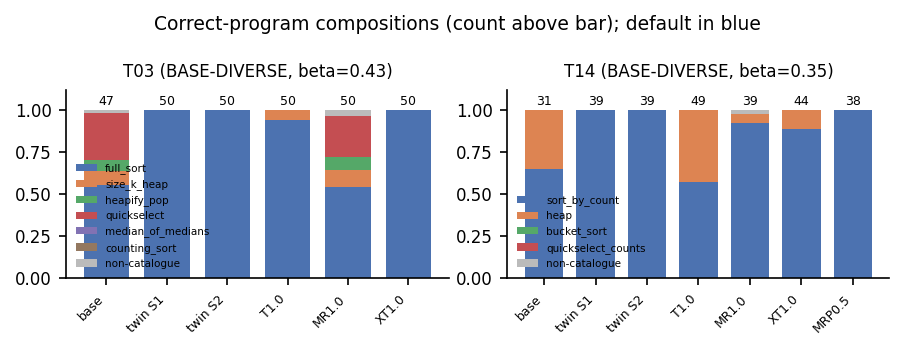

In [23]:
fig_compositions(c1, conf)

**Fig. 4: effect sizes.** This is the per-slot difference in the correct off-default rate y between T and each control on S2, with Newcombe 95% intervals and Holm-adjusted p over the demo family. T14's intervals sit clearly right of 0. T03's interval against MR sits left of 0: random noise beats the base state there.

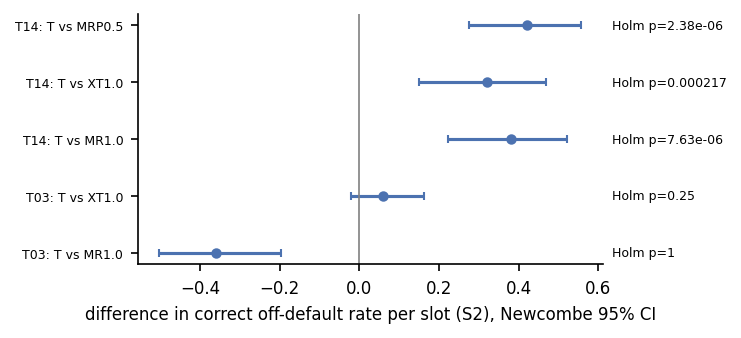

In [24]:
fig_forest(conf)

### Fig. 5: activation geometry at the plan site (`results/geometry.json`)

`src/geometry5.py` embedded the cached residual-stream states of Qwen3-8B (d = 4096) into 2-D. It used metric MDS (stress-1 is reported in each title) and Isomap, at the task-spec mean (S) and the read position (R) of blocks 18, 23 and 27. The points are:
- the forced **"Implement X" centroids**, one per catalogue algorithm and per model (▲ instruct, ▼ base);
- the twins (● blue instruct, ● green base);
- the hooked states: **T(λ\*)** as red squares, READ in pink, ISO(1) as grey ×.

The 6.3 GB state cache is not published, so the cell redraws the stored embeddings of the two demo tasks with the original plotting function. It then prints the **fraction of the instruct → base gap** that the transplanted state covers. At S27 that is about 88-89%: the transplanted plan state still sits near the base twin. At R it is only 18-31%: the read position, where decoding starts, stays much closer to the instruct model.

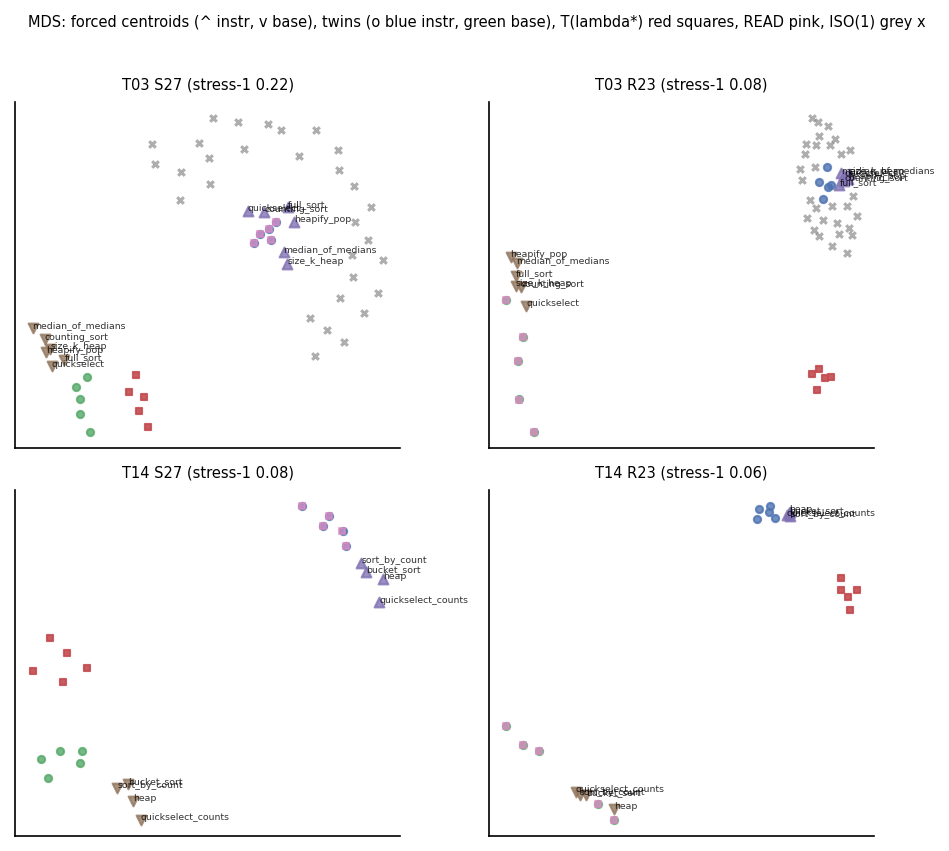

fraction of the instruct -> base twin gap covered by T(lambda*)  (geometry5: T_frac_of_gap_from_instr)
task     S18    S23    S27    R18    R23    MDS stress-1 S27/R23
T03     1.00   1.00   0.88   0.18   0.30             0.22 / 0.08
T14     1.00   1.00   0.89   0.18   0.31             0.08 / 0.06


In [25]:
fig_geometry(META["geometry"])
print("fraction of the instruct -> base twin gap covered by T(lambda*)  (geometry5: T_frac_of_gap_from_instr)")
sites = ("S18", "S23", "S27", "R18", "R23")
print(f"{'task':5}" + "".join(f"{s:>7}" for s in sites) + f"{'MDS stress-1 S27/R23':>24}")
for t, pan in META["geometry"]["panels"].items():
    print(f"{t:5}" + "".join(f"{pan[s]['T_frac_of_gap_from_instr']:7.2f}" for s in sites)
          + f"{pan['S27']['mds_stress1']:>17.2f} / {pan['R23']['mds_stress1']:.2f}")

## 7. Results summary

The table holds the key numbers recomputed in this notebook, next to the full run's verdict. After it come:
- the paired per-template view behind the "templates T > control" robustness count. The TWIN bars are zero on every template, because the twin never writes a correct off-default program on these slots;
- one CRN slot where the transplant changed the algorithm. The prompt and the uniform stream are identical; only the prefill states differ.

**What T14's `heap` label means.** The label worker's runtime tracer records the library calls a program makes. CPython implements `Counter.most_common(k)` with `heapq.nlargest`, so a `most_common(k)` program is labelled `heap`, while the twin's default `sorted(count.items(), ...)[:k]` is labelled `sort_by_count`. The last lines of the cell count these idioms in the demo programs: every one of the 21 `heap` programs under T(1) is `most_common(k)`. That is also the base model's main runner-up form. In the artifact's `data/samples.jsonl`, 8 of the base model's 11 correct T14 `heap` programs use `most_common(k)`, and 2 call `heapq` directly. So the transplant reproduces the base model's dominant idiom; it does not produce a hand-written heap.

Claim B, frozen rule, demo tasks: DISCONFIRMED  (PASS 1 of 2 demo tasks; n_div = 5 -> 4 needed; condition (iii) fails on 1)
Claim B, frozen rule, full run:   DISCONFIRMED  (PASS 1 of 5; condition (iii) fails on 4)

task  arm      pass  off-default/correct  modal off-default T vs arm b:c p one-sided  Holm demo  Holm full templ. T>arm
T03   TWIN     1.00                 0/50               None
T03   T1.0     1.00                 3/50        size_k_heap 
T03   MR1.0    1.00                21/50        quickselect         2:20           1          1          1          0/5
T03   XT1.0    1.00                 0/50               None          3:0        0.12       0.25          1          2/5
      rule: (i) pass True  (ii) share False  (iii) controls False  (iv) lands on r_t=quickselect False  ->  PASS False

T14   TWIN     0.78                 0/39               None
T14   T1.0     0.98                21/49               heap 
T14   MR1.0    0.78                 2/39               heap    

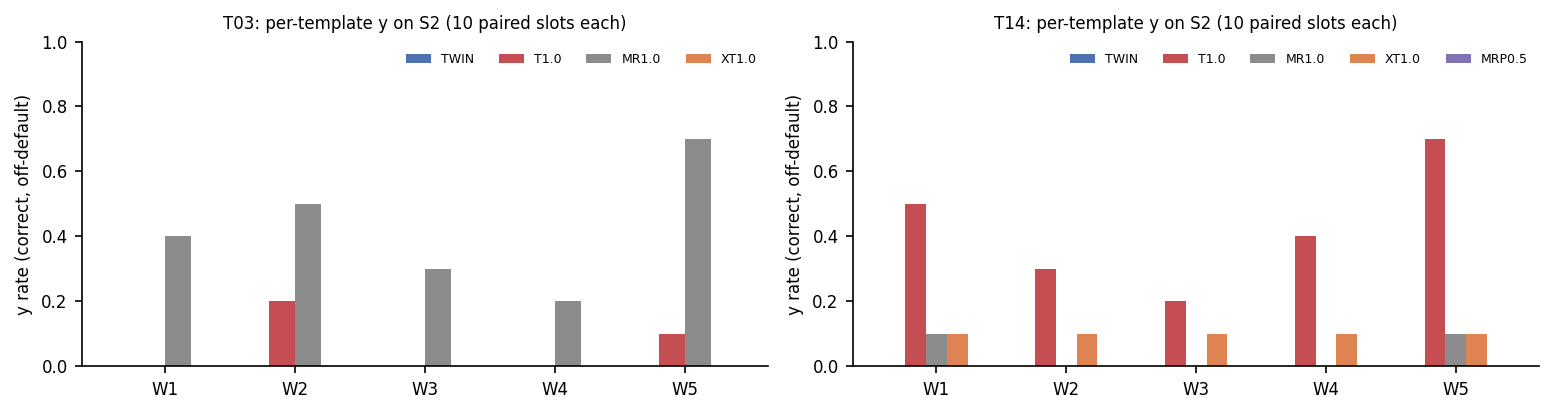

CRN slot T14|W1|12: same prompt, same uniform stream -- only the prefill states at blocks 12-23 differ

PROMPT:
  Do not use picture for this task. . .

  Task: write a Python function solve(nums, k) that returns the k values that occur most often in nums, as a list in any order. The argument nums is a list of integers with 1 <= len(nums) <= 10000 and every value between -10000 and 10000 inclusive; k is an integer between 1 and the number of distinct values in nums. The inputs are chosen so that the answer is unique: the k-th and (k+1)-th highest frequencies always differ.

  Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation.

--- TWIN (label|tests: sort_by_count|pass) ---
  from collections import Counter

  def solve(nums, k):
      count = Counter(nums)
      sorted_counts = sorted(count.items(), key=lambda x: (-x[1], x[0]))
      result = [item[0] for item in sorted_coun

In [26]:
v, vr = conf["verdict"], ref["verdict"]
print(f"Claim B, frozen rule, demo tasks: {v['verdict']}  (PASS {v['n_pass']} of {v['n_decisive']} demo tasks; "
      f"n_div = {c1['n_div']} -> {v['needed']} needed; condition (iii) fails on {v['n_iii_fail']})")
print(f"Claim B, frozen rule, full run:   {vr['verdict']}  (PASS {vr['n_pass']} of {vr['n_decisive']}; "
      f"condition (iii) fails on {vr['n_iii_fail']})\n")
print(f"{'task':5} {'arm':7} {'pass':>5} {'off-default/correct':>20} {'modal off-default':>18} {'T vs arm b:c':>12} "
      f"{'p one-sided':>11} {'Holm demo':>10} {'Holm full':>10} {'templ. T>arm':>12}")
for t, r in conf["per_task"].items():
    tw = r["twin_S2"]
    print(f"{t:5} {'TWIN':7} {tw['pass']:5.2f} {str(tw['k_off']) + '/' + str(tw['n_correct']):>20} "
          f"{str(tw['modal_correct_nondefault']):>18}")
    for a, c in r["arms"].items():
        m, cc = c.get("mcnemar_T_vs_this"), c.get("control_class")
        extra = (f"{str(m['b']) + ':' + str(m['c']):>12} {m['p_one']:11.2g} {r['holm'][cc]:10.2g} "
                 f"{ref['holm_adjusted'][t + '|' + cc]:10.2g} "
                 f"{str(c['template_robustness']['n_templates_arm_gt_control']) + '/5':>12}") if m else ""
        print(f"{t:5} {a:7} {c['pass']:5.2f} {str(c['k_off']) + '/' + str(c['n_correct']):>20} "
              f"{str(c['modal_correct_nondefault']):>18} {extra}")
    ru = r["rule"]
    print(f"      rule: (i) pass {ru['i_pass']}  (ii) share {ru['ii_share']}  (iii) controls {ru['iii_controls']}  "
          f"(iv) lands on r_t={c1['per_task'][t]['r_t']} {ru['iv_landing']}  ->  PASS {ru['PASS']}\n")

# per-template correct off-default rate y (paired CRN slots; the 'templates T > control' count)
fig, axes = plt.subplots(1, len(conf["per_task"]), figsize=(5.2 * len(conf["per_task"]), 2.8), squeeze=False)
for ax, (t, r) in zip(axes[0], conf["per_task"].items()):
    d, ct = c1["per_task"][t]["default"], catalogue(t)
    arms = list(r["arms"])
    series = [("TWIN", [float(np.mean([A.y_off(x, d, ct) for x in sel(labs, t, "TWIN", S2_SLOTS_50) if x["template"] == w]))
                        for w in TEMPLATE_IDS])]
    first = r["arms"][arms[1]]["template_robustness"]["by_template"]
    series.append((arms[0], [first[w]["y_rate_arm"] for w in TEMPLATE_IDS]))
    for a in arms[1:]:
        bt = r["arms"][a]["template_robustness"]["by_template"]
        series.append((a, [bt[w]["y_rate_control"] for w in TEMPLATE_IDS]))
    wdt = 0.8 / len(series)
    for i, (name, ys) in enumerate(series):
        ax.bar(np.arange(len(TEMPLATE_IDS)) + (i - (len(series) - 1) / 2) * wdt, ys, wdt, label=name,
               color=["#4C72B0", "#C44E52", "#8C8C8C", "#DD8452", "#8172B3"][i])
    ax.set_xticks(range(len(TEMPLATE_IDS)))
    ax.set_xticklabels(TEMPLATE_IDS)
    ax.set_ylim(0, 1)
    ax.set_ylabel("y rate (correct, off-default)")
    ax.set_title(f"{t}: per-template y on S2 (10 paired slots each)", fontsize=8)
    ax.legend(fontsize=6, frameon=False, ncol=len(series))
plt.tight_layout()
plt.show()

# one CRN slot where the transplant reopened the base runner-up
t = "T14"
d, r_t = c1["per_task"][t]["default"], c1["per_task"][t]["r_t"]
e = next(e for e in EXAMPLES if e["metadata_task"] == t and e["predict_T1_0"] == f"{r_t}|pass" and e["output"] == f"{d}|pass")
print(f"CRN slot {e['metadata_crn_key']}: same prompt, same uniform stream -- only the prefill states at blocks 12-23 differ\n")
print("PROMPT:\n" + textwrap.indent(e["input"], "  ") + "\n")
for arm, lab in (("TWIN", e["output"]), ("T1.0", e["predict_T1_0"])):
    print(f"--- {arm} (label|tests: {lab}) ---")
    print(textwrap.indent(e["metadata_programs"][arm].strip(), "  ") + "\n")

# how the correct 'heap' programs of T14 are written, per arm (Counter.most_common(k) runs heapq.nlargest)
idiom = defaultdict(Counter)
for x in labs:
    if x["task"] == t and A.is_correct(x) and x["label"] == r_t:
        idiom[x["arm"]]["Counter.most_common(k)" if re.search(r"most_common\(\s*k\s*\)", x["code"])
                        else ("heapq directly" if "heapq" in x["code"] else "other")] += 1
print(f"correct '{r_t}' programs on {t} by idiom:", {a: dict(c) for a, c in idiom.items()})